# Laboratorium 4 — Algorytmy grupowania danych

## Autor - Cyprian Kozubek nr.indeksu 272959

## Cel ćwiczenia
Celem ćwiczenia jest analiza działania algorytmów grupowania:
- K-Means
- DBSCAN

Badanie obejmuje:
- wpływ hiperparametrów,
- ocenę jakości klasteryzacji,
- wizualizację wyników,
- porównanie algorytmów na różnych zbiorach danych.

Analizowane zbiory:
- IRIS
- SEEDS
- GLASS

## Importy

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
)

from sklearn.metrics.cluster import contingency_matrix

from ucimlrepo import fetch_ucirepo

# konfiguracja wykresów
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# seed dla powtarzalności
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Wczytanie danych i wstępne przetwarzanie

### Zbiór danych - IRIS

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

INFO:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
None

DESCRIBE:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Brakujące wartości:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


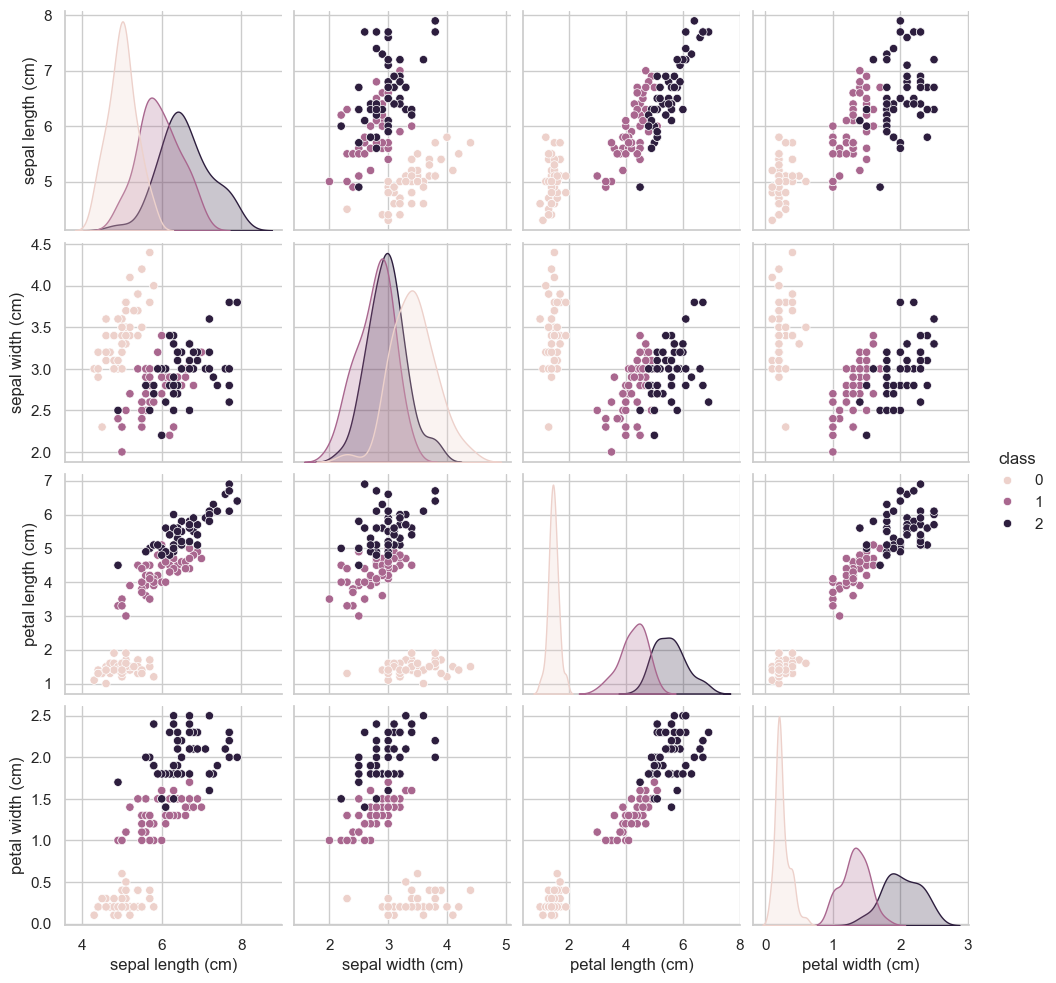

In [2]:
iris = load_iris(as_frame=True)

X_iris = iris.data
y_iris = iris.target

print(X_iris.head())

print("\nINFO:")
print(X_iris.info())

print("\nDESCRIBE:")
display(X_iris.describe())

print("\nBrakujące wartości:")
print(X_iris.isnull().sum())

iris_df = X_iris.copy()
iris_df["class"] = y_iris

sns.pairplot(iris_df, hue="class")
plt.show()

scaler_iris = StandardScaler()

X_iris_scaled = scaler_iris.fit_transform(X_iris)

### Zbiór danych - SEEDS

,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coefficient,kernel_groove_length,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   area                   210 non-null    float64
 1   perimeter              210 non-null    float64
 2   compactness            210 non-null    float64
 3   kernel_length          210 non-null    float64
 4   kernel_width           210 non-null    float64
 5   asymmetry_coefficient  210 non-null    float64
 6   kernel_groove_length   210 non-null    float64
 7   class                  210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB
None


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coefficient,kernel_groove_length,class
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


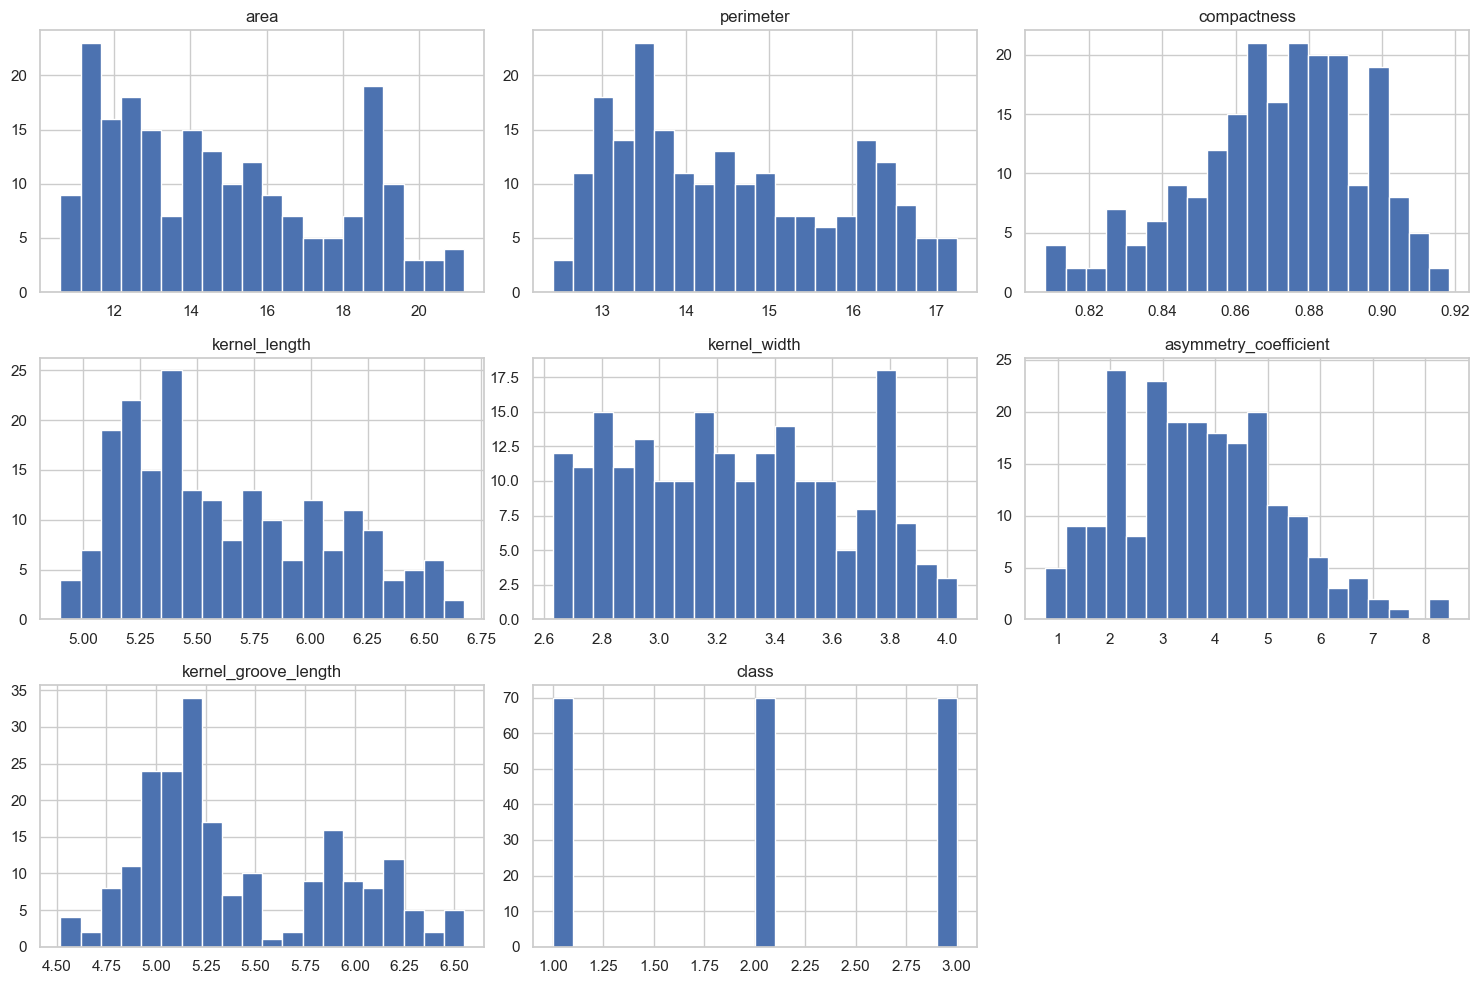

In [3]:
seed_columns = [
    "area",
    "perimeter",
    "compactness",
    "kernel_length",
    "kernel_width",
    "asymmetry_coefficient",
    "kernel_groove_length",
    "class"
]

seeds_df = pd.read_csv(
    "seeds/seeds_dataset.txt",
    sep=r"\s+",
    header=None,
    names=seed_columns
)

display(seeds_df.head())

print(seeds_df.info())

display(seeds_df.describe())

seeds_df.hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

X_seeds = seeds_df.drop(columns=["class"])
y_seeds = seeds_df["class"]

scaler_seeds = StandardScaler()

X_seeds_scaled = scaler_seeds.fit_transform(X_seeds)

### Zbiór danych - GLASS

In [4]:
glass_identification = fetch_ucirepo(id=42)

X_glass = glass_identification.data.features
y_glass = glass_identification.data.targets

print(glass_identification.metadata)

print(glass_identification.variables)

display(X_glass.head())
display(X_glass.describe())

print(y_glass.value_counts())

scaler_glass = StandardScaler()

X_glass_scaled = scaler_glass.fit_transform(X_glass)

{'uci_id': 42, 'name': 'Glass Identification', 'repository_url': 'https://archive.ics.uci.edu/dataset/42/glass+identification', 'data_url': 'https://archive.ics.uci.edu/static/public/42/data.csv', 'abstract': 'From USA Forensic Science Service; 6 types of glass; defined in terms of their oxide content (i.e. Na, Fe, K, etc)', 'area': 'Physics and Chemistry', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 214, 'num_features': 9, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Type_of_glass'], 'index_col': ['Id_number'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1987, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5WW2P', 'creators': ['B. German'], 'intro_paper': None, 'additional_info': {'summary': 'Vina conducted a comparison test of her rule-based system, BEAGLE, the nearest-neighbor algorithm, and discriminant analysis.  BEAGLE is a product available through VRS Consulting, In

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000


Type_of_glass
2                76
1                70
7                29
3                17
5                13
6                 9
Name: count, dtype: int64


### Funkcje pomocniczne

In [5]:
def purity_score(true_labels, pred_labels):
    """Oblicza purity score."""
    cm = contingency_matrix(true_labels, pred_labels)
    return np.sum(np.amax(cm, axis=0)) / np.sum(cm)


def compute_metrics(X, labels, true_labels=None):
    """Zwraca słownik z metrykami jakości klasteryzacji."""
    metrics = {}
    mask = labels != -1
    try:
        if len(set(labels[mask])) >= 2:
            metrics["silhouette"] = silhouette_score(
                X[mask],
                labels[mask]
            )
            metrics["davies_bouldin"] = davies_bouldin_score(
                X[mask],
                labels[mask]
            )
        else:
            metrics["silhouette"] = np.nan
            metrics["davies_bouldin"] = np.nan
    except Exception:
        metrics["silhouette"] = np.nan
        metrics["davies_bouldin"] = np.nan

    if true_labels is not None:
        metrics["adjusted_rand"] = adjusted_rand_score(
            true_labels,
            labels
        )
        metrics["purity"] = purity_score(
            true_labels,
            labels
        )
    return metrics

def plot_clusters_2d(X, labels, title):
    """PCA -> 2D scatter plot."""
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_pca = pca.fit_transform(X)
    plt.figure(figsize=(8, 6))

    scatter = plt.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="tab10"
    )
    plt.title(title)
    plt.xlabel("PCA 1")
    plt.ylabel("PCA 2")
    plt.colorbar(scatter)
    plt.show()

def plot_metrics_vs_param(param_values, metrics_dict, param_name):

    for metric_name, values in metrics_dict.items():

        plt.figure(figsize=(8, 5))

        plt.plot(param_values, values, marker="o")

        plt.title(f"{metric_name} vs {param_name}")
        plt.xlabel(param_name)
        plt.ylabel(metric_name)

        plt.grid(True)
        plt.show()

## Badanie algorytmu K-Means

### K-Means — IRIS (Sanity check)

{'silhouette': 0.4798814508199817, 'davies_bouldin': 0.7893630242997912, 'adjusted_rand': 0.432804702527474, 'purity': np.float64(0.6666666666666666)}


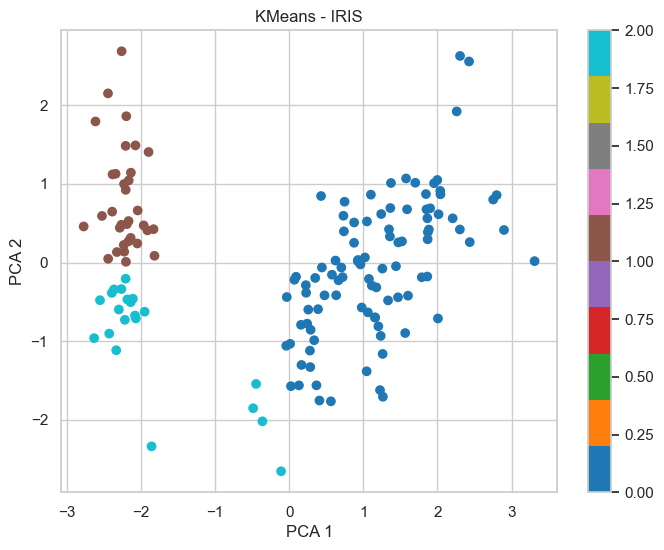

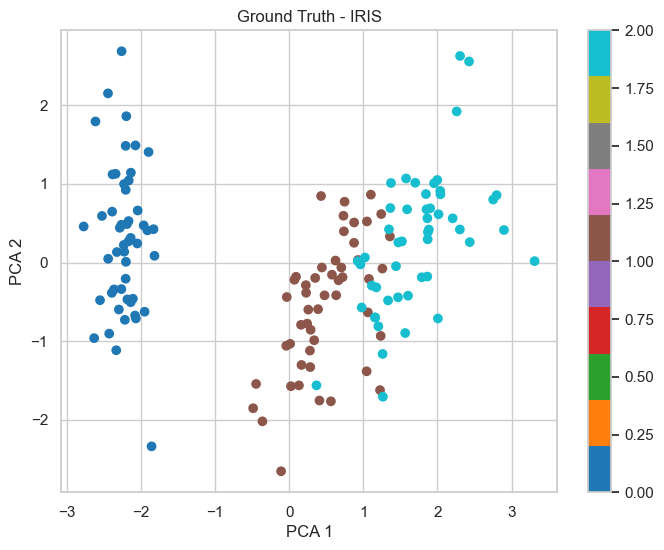

In [59]:
 kmeans_iris = KMeans(
    n_clusters=3,
    random_state=RANDOM_STATE
)
iris_labels = kmeans_iris.fit_predict(X_iris_scaled)

metrics_iris = compute_metrics(
    X_iris_scaled,
    iris_labels,
    y_iris
)
print(metrics_iris)

plot_clusters_2d(
    X_iris_scaled,
    iris_labels,
    "KMeans - IRIS"
)
plot_clusters_2d(
    X_iris_scaled,
    y_iris,
    "Ground Truth - IRIS"
)

### Wnioski
#### Wizualizacja (PCA):
* Algorytm błędnie rozbił naturalnie zwartą grupę po lewej stronie na dwa klastry, jednocześnie łącząc dwie pozostałe klasy w jeden wspólny zbiór. Podział przebiegł wzdłuż osi o największej wariancji, ignorując faktyczną strukturę gatunkową danych.

#### Wyniki:
* Metryka Purity (0.67) oraz ARI (0.43) potwierdzają niską zgodność z etykietami, wynikającą z połączenia dwóch gatunków w jedną grupę.
* Średni wynik Silhouette (0.48) sugeruje poprawną spójność geometryczną klastrów, mimo ich całkowitego niedopasowania do rzeczywistych klas.
* Davies-Bouldin Index (0.79): Stosunkowo niska (dobra) wartość, co oznacza, że z perspektywy geometrycznej klastry są dobrze odseparowane i zwarte. Jest to jednak "pułapka" tej metryki, która faworyzuje klastry sferyczne (charakterystyczne dla K-Means) niezależnie od prawdziwych etykiet klas.

### K-Means - badanie parametrów

### Badanie parametru n_clusters dla GLASS i SEEDS


  SEEDS — badanie n_clusters


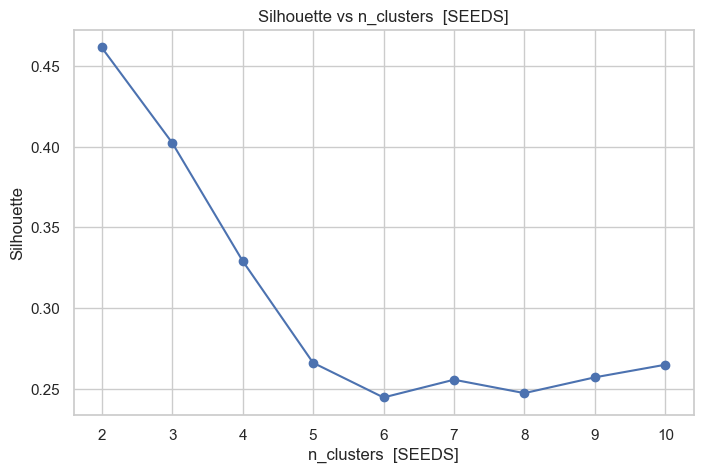

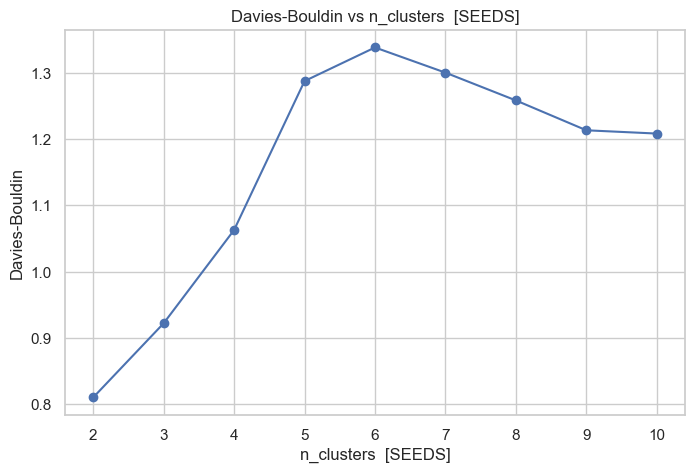

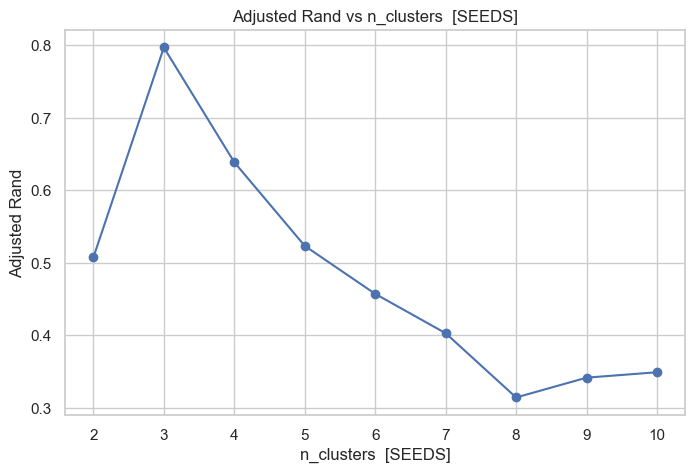

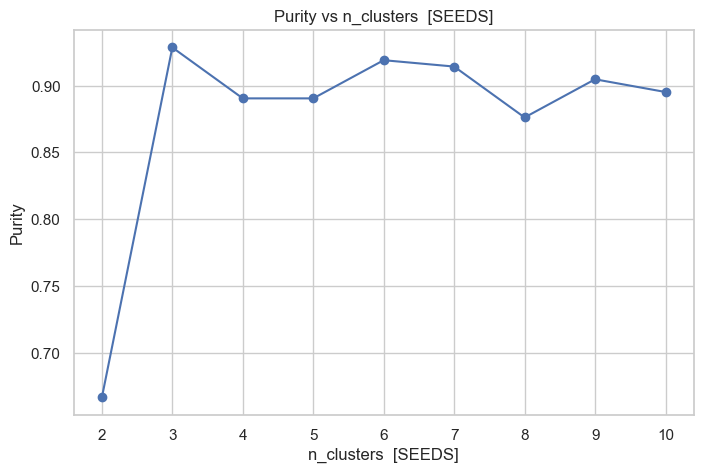

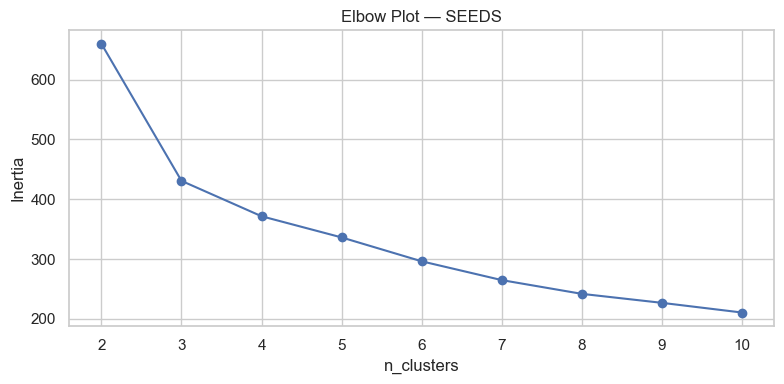


  GLASS — badanie n_clusters


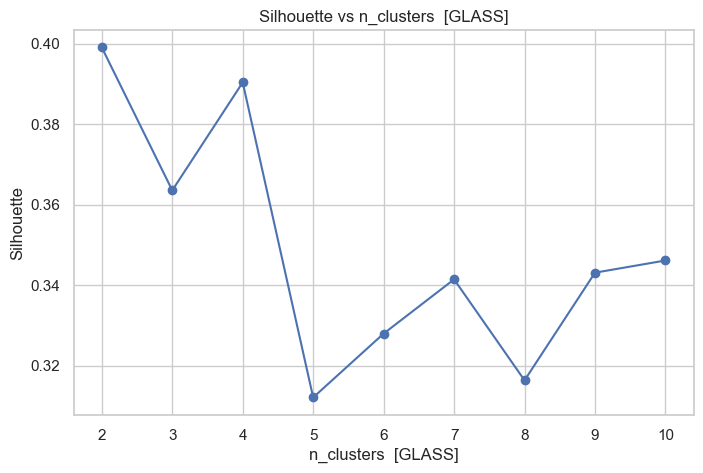

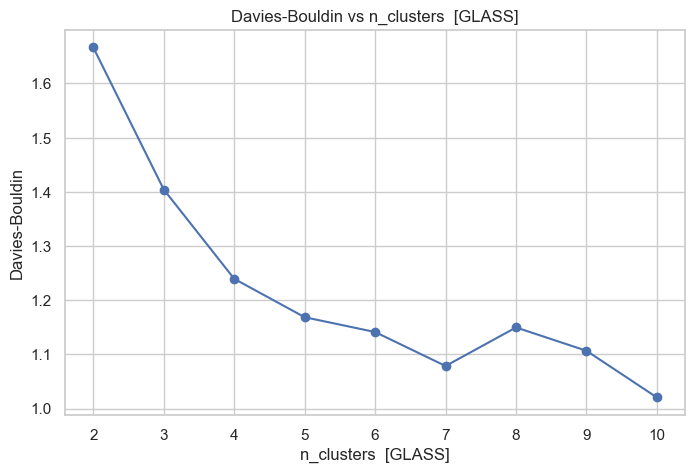

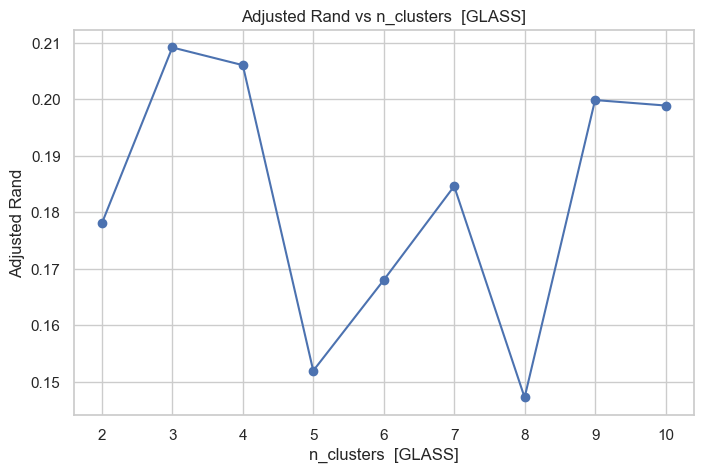

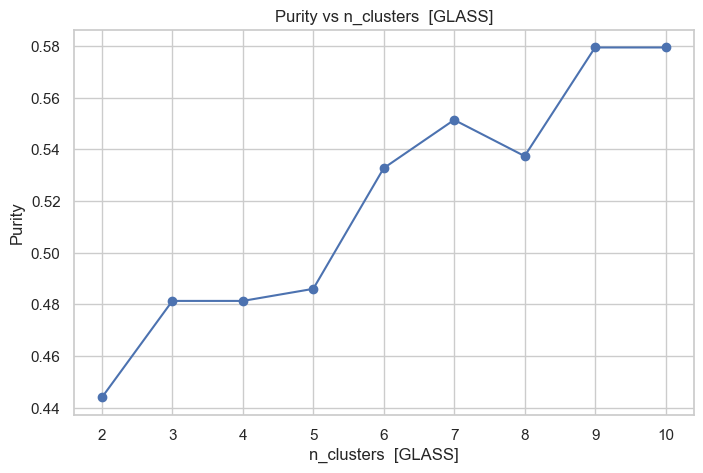

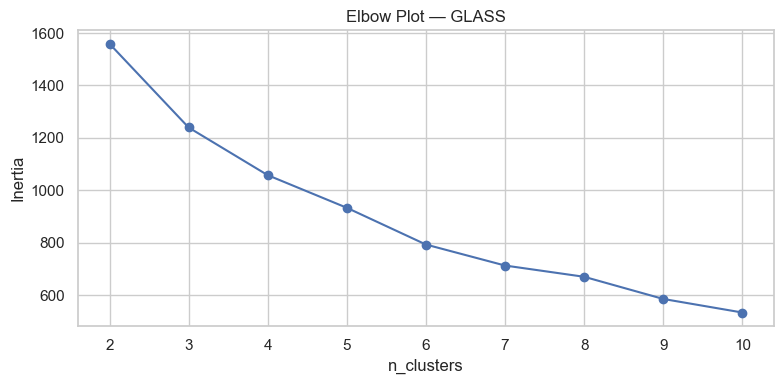

In [60]:
datasets = {
    "SEEDS": (X_seeds_scaled, y_seeds),
    "GLASS": (X_glass_scaled, y_glass.values.ravel())
}
k_values = range(2, 11)
for dataset_name, (X_data, y_data) in datasets.items():
    print(f"\n  {dataset_name} — badanie n_clusters")

    silhouettes, db_indexes, ari_scores, purity_scores, inertias = [], [], [], [], []

    for k in k_values:
        model  = KMeans(n_clusters=k, random_state=RANDOM_STATE)
        labels = model.fit_predict(X_data)
        m = compute_metrics(X_data, labels, y_data)
        silhouettes.append(m["silhouette"])
        db_indexes.append(m["davies_bouldin"])
        ari_scores.append(m["adjusted_rand"])
        purity_scores.append(m["purity"])
        inertias.append(model.inertia_)

    plot_metrics_vs_param(
        list(k_values),
        {"Silhouette": silhouettes, "Davies-Bouldin": db_indexes,
         "Adjusted Rand": ari_scores, "Purity": purity_scores},
        f"n_clusters  [{dataset_name}]"
    )

    plt.figure(figsize=(8, 4))
    plt.plot(list(k_values), inertias, marker="o")
    plt.title(f"Elbow Plot — {dataset_name}")
    plt.xlabel("n_clusters"); plt.ylabel("Inertia")
    plt.grid(True); plt.tight_layout(); plt.show()

### Wnioski:
#### Zbiór SEEDS
* Elbow Plot (Inertia): Wykres wykazuje zauważalne zagięcie (tzw. "łokieć") przy wartości $k=3$, co sugeruje, że jest to optymalna liczba klastrów dla tego zbioru.
* Silhouette & Davies-Bouldin: Z czysto geometrycznego punktu widzenia obie metryki osiągają najlepsze wyniki dla $k=2$ (najwyższy Silhouette, najniższy DB), co wskazuje, że dane najłatwiej podzielić na dwie wysoce spójne grupy.
* Adjusted Rand Index (ARI) & Purity: Wyraźny skok i maksymalne wartości obu metryk dla $k=3$ jednoznacznie udowadniają, że podział na 3 klastry najlepiej odwzorowuje rzeczywiste etykiety trzech odmian ziaren.
#### Zbiór GLASS
* Elbow Plot (Inertia): Krzywa opada bardzo płynnie, bez wyraźnego punktu przegięcia, co od razu sugeruje skomplikowaną strukturę danych ze słabo odseparowanymi klastrami.
* Silhouette & Davies-Bouldin: Wartości Silhouette są ogólnie niskie, a indeks DB spada wraz z rosnącym $k$, co potwierdza brak naturalnych, wyraźnie oddzielonych od siebie sferycznych skupień.
* Adjusted Rand Index (ARI) & Purity: Ekstremalnie niskie wartości ARI oraz powolny wzrost Purity przy rosnącym $k$ dowodzą, że K-Means nie potrafi poprawnie zidentyfikować rzeczywistych klas szkła niezależnie od wybranej liczby klastrów.

### Badanie parametru n_init dla GLASS i SEEDS


  SEEDS — badanie n_init (k=3)



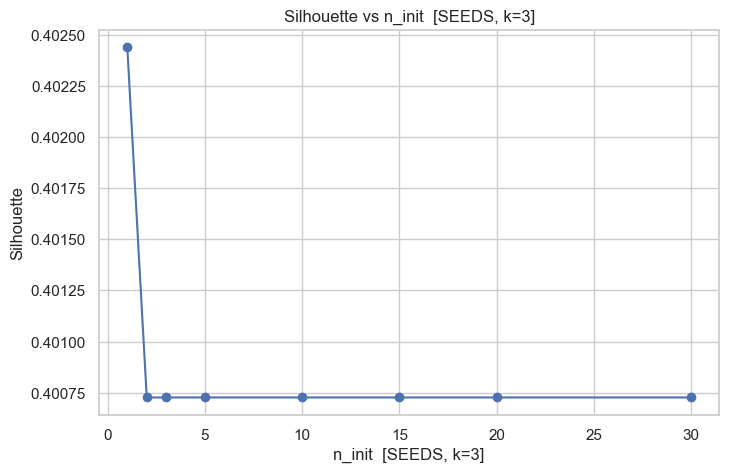

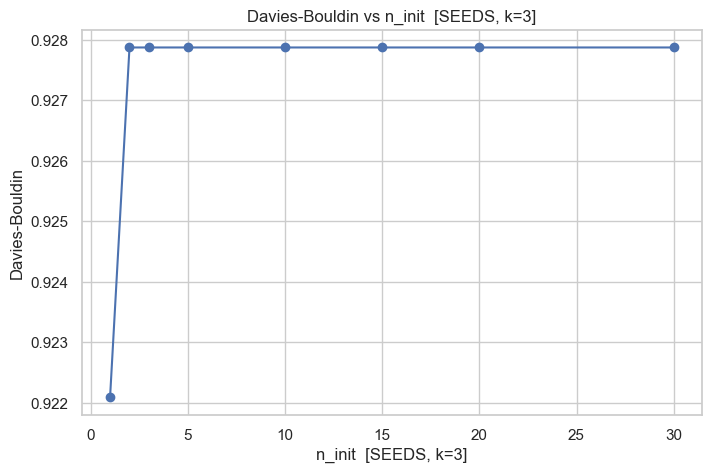

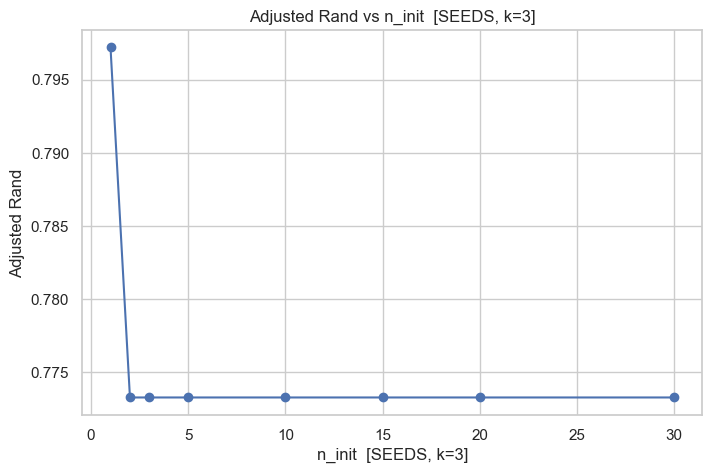

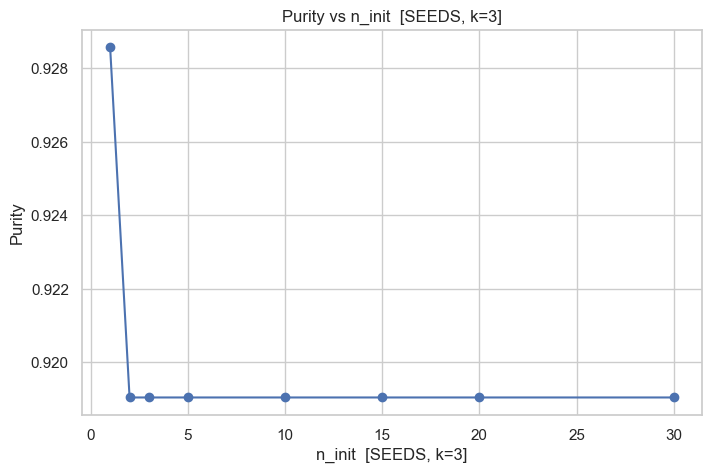


  GLASS — badanie n_init (k=6)



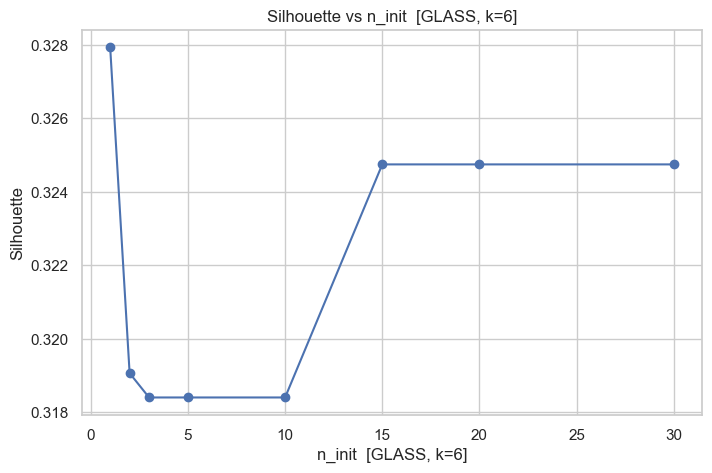

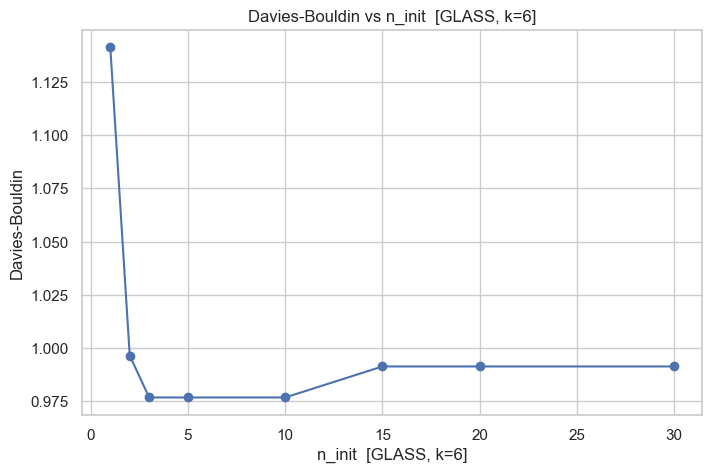

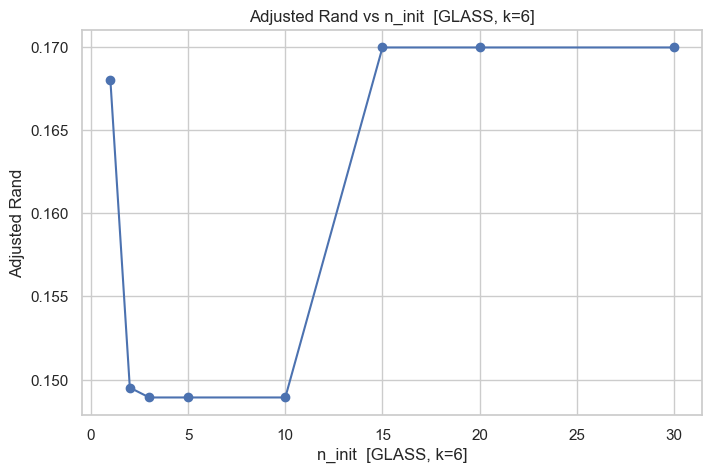

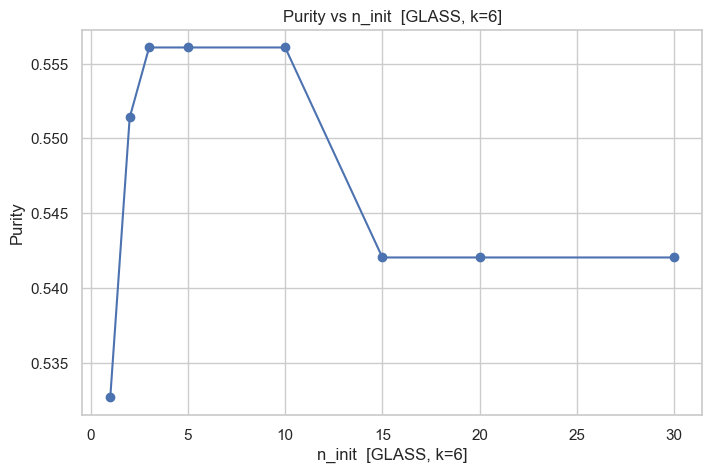

In [61]:
n_init_values = [1, 2, 3, 5, 10, 15, 20, 30]

best_k = {"SEEDS": 3, "GLASS": 6}

for dataset_name, (X_data, y_data) in datasets.items():
    k = best_k[dataset_name]
    print(f"\n  {dataset_name} — badanie n_init (k={k})\n")

    silhouettes, db_indexes, ari_scores, purity_scores = [], [], [], []

    for n_init in n_init_values:
        model  = KMeans(n_clusters=k, n_init=n_init, random_state=RANDOM_STATE)
        labels = model.fit_predict(X_data)
        m = compute_metrics(X_data, labels, y_data)
        silhouettes.append(m["silhouette"])
        db_indexes.append(m["davies_bouldin"])
        ari_scores.append(m["adjusted_rand"])
        purity_scores.append(m["purity"])

    plot_metrics_vs_param(
        n_init_values,
        {"Silhouette": silhouettes, "Davies-Bouldin": db_indexes,
         "Adjusted Rand": ari_scores, "Purity": purity_scores},
        f"n_init  [{dataset_name}, k={k}]"
    )

`n_init` kontroluje liczbę losowych inicjalizacji centroidów; najlepszy wynik (minimalna inercja) jest zatrzymywany.

### Wnioski:
#### Zbiór SEEDS
* Stabilność metryk: Wszystkie wykresy (Silhouette, ARI, Purity, DB) wykazują całkowicie płaski przebieg od wartości n_init=1 wzwyż. Oznacza to, że zbiór ten posiada na tyle wyraźną strukturę, że algorytm trafia do optymalnego rozwiązania już przy pierwszej próbie.

* Wnioski numeryczne: Stałe, wysokie wartości ARI oraz Purity dowodzą, że zwiększanie liczby inicjalizacji nie jest konieczne dla uzyskania powtarzalnych i poprawnych wyników w przypadku ziaren.

#### Zbiór GLASS
* Wahania początkowe: Na wykresach (szczególnie ARI i Silhouette) widoczna jest niewielka niestabilność dla bardzo małych wartości n_init. Sugeruje to, że przy pojedynczym losowaniu algorytm może utknąć w mniej korzystnym minimum lokalnym ze względu na szum w danych.

* Stabilizacja: Powyżej wartości n_init=5 metryki stabilizują się na stałym poziomie. Potwierdza to, że zbiór GLASS jest trudniejszy do grupowania, ale standardowa liczba inicjalizacji (powyżej 10) jest w pełni wystarczająca do osiągnięcia optymalnej zbieżności.

### Badanie parametru max_iter dla GLASS i SEEDS


  SEEDS — badanie max_iter (k=3)



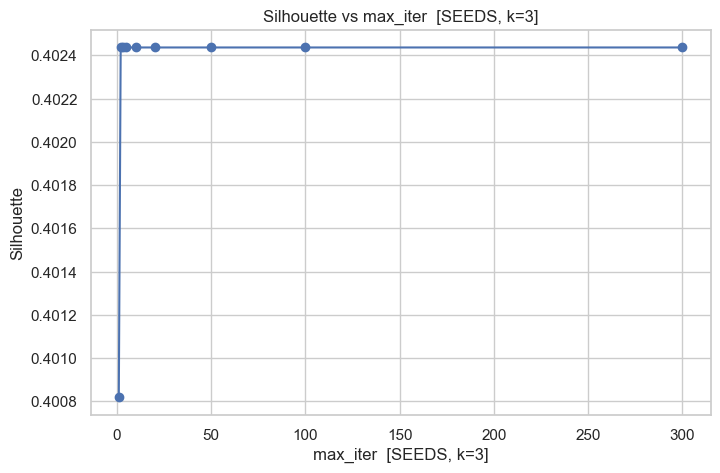

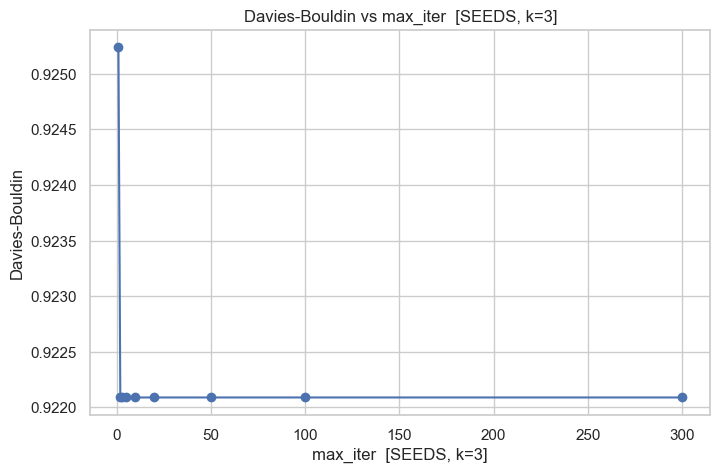

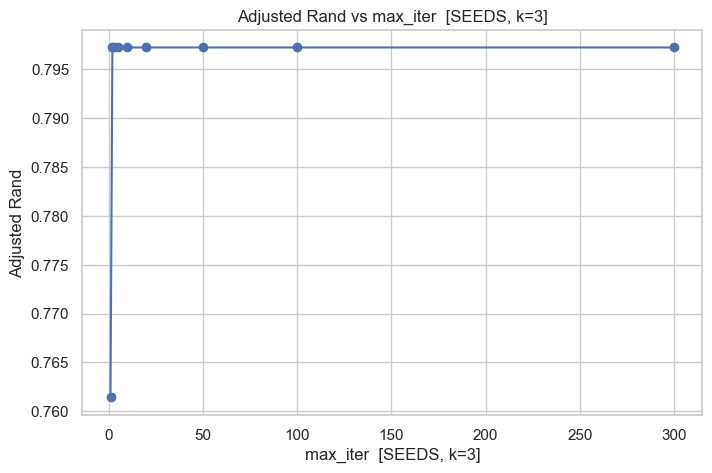

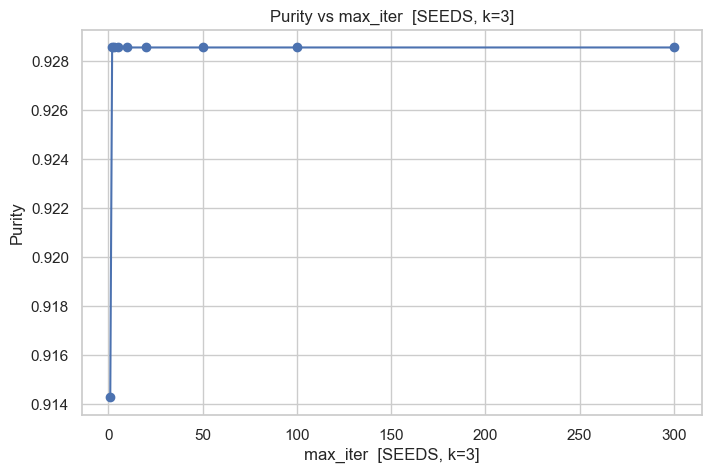


  GLASS — badanie max_iter (k=6)



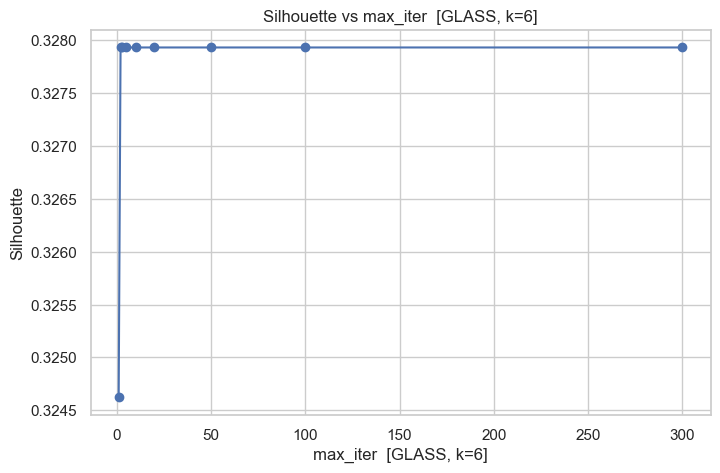

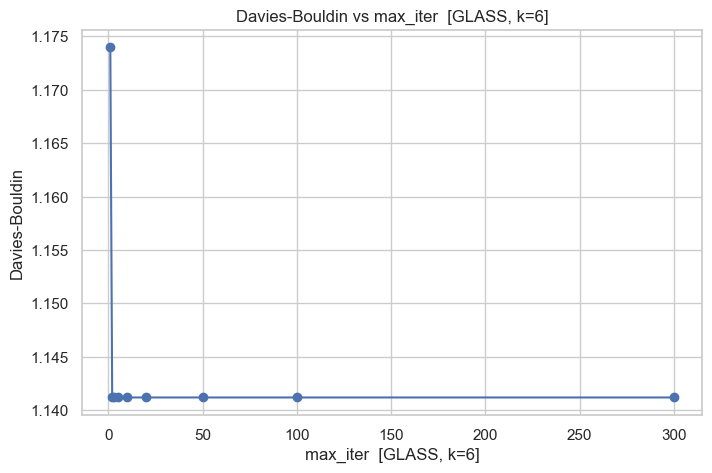

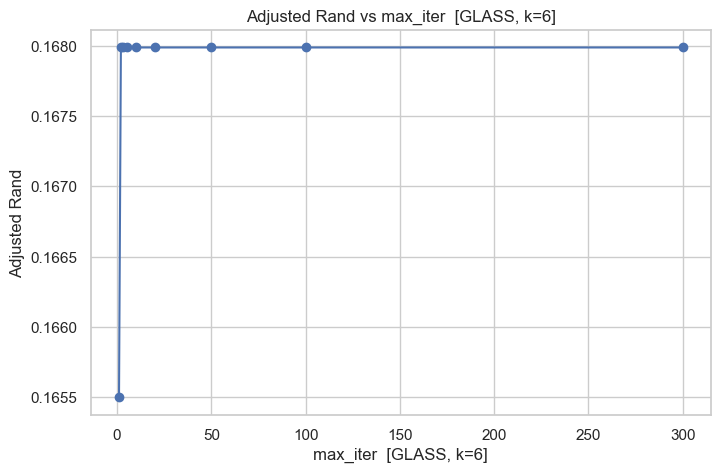

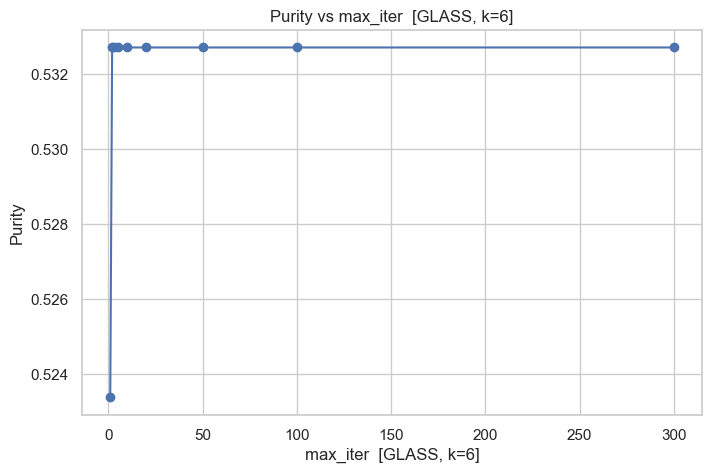

In [62]:
max_iter_values = [1, 2, 3, 5, 10, 20, 50, 100, 300]

for dataset_name, (X_data, y_data) in datasets.items():
    k = best_k[dataset_name]
    print(f"\n  {dataset_name} — badanie max_iter (k={k})\n")

    silhouettes, db_indexes, ari_scores, purity_scores = [], [], [], []

    for max_iter in max_iter_values:
        model = KMeans(n_clusters=k, max_iter=max_iter, random_state=RANDOM_STATE)
        labels = model.fit_predict(X_data)
        m = compute_metrics(X_data, labels, y_data)
        silhouettes.append(m["silhouette"])
        db_indexes.append(m["davies_bouldin"])
        ari_scores.append(m["adjusted_rand"])
        purity_scores.append(m["purity"])

    plot_metrics_vs_param(
        max_iter_values,
        {"Silhouette": silhouettes, "Davies-Bouldin": db_indexes,
         "Adjusted Rand": ari_scores, "Purity": purity_scores},
        f"max_iter  [{dataset_name}, k={k}]"
    )


`max_iter` wyznacza twardą granicę liczby kroków aktualizacji centroidów (algorytm zatrzymuje się wcześniej po osiągnięciu zbieżności).

### Wnioski:
#### Zbiór SEEDS
* Szybkość zbieżności: Wszystkie metryki (Silhouette, ARI, Purity, DB) utrzymują stałe wartości już od najniższej badanej liczby iteracji. Sugeruje to, że algorytm bardzo szybko osiąga stabilne położenie centroidów, a struktura danych jest łatwo definiowalna.

* Wyniki numeryczne: Brak zmian w wartościach takich jak ARI czy Purity przy zwiększaniu max_iter dowodzi, że domyślne limity iteracji są znacznie powyżej faktycznych potrzeb tego zbioru.

#### Zbiór GLASS
* Charakterystyka procesu: Podobnie jak w zbiorze SEEDS, wykresy metryk jakościowych są płaskie w całym zakresie badanego parametru. Oznacza to, że mimo większego skomplikowania zbioru GLASS, optymalizacja odległości euklidesowych kończy się bardzo szybko.

* Wnioski numeryczne: Stałe, choć niskie wartości, wskazują, że problemem w przypadku szkła nie jest brak czasu na zbieżność algorytmu, lecz sama specyfika danych (duże nachodzenie na siebie klas).

### Wizualicja K-Means


### Zbiór IRIS


IRIS | KMeans | k=2


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.58175,0.593313,0.568116,0.666667


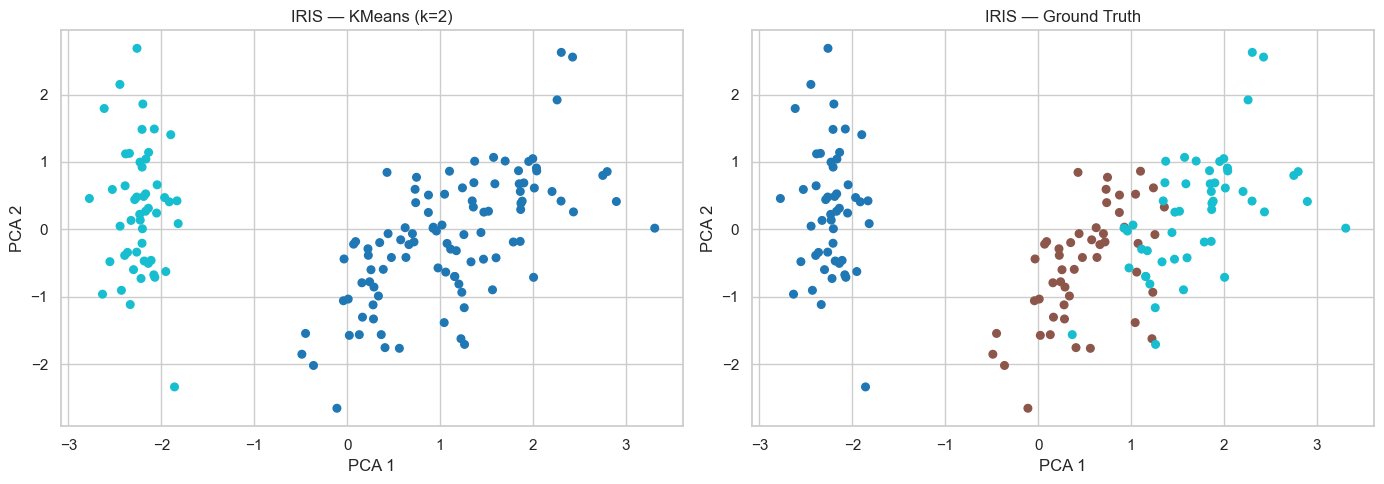


IRIS | KMeans | k=3


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.479881,0.789363,0.432805,0.666667


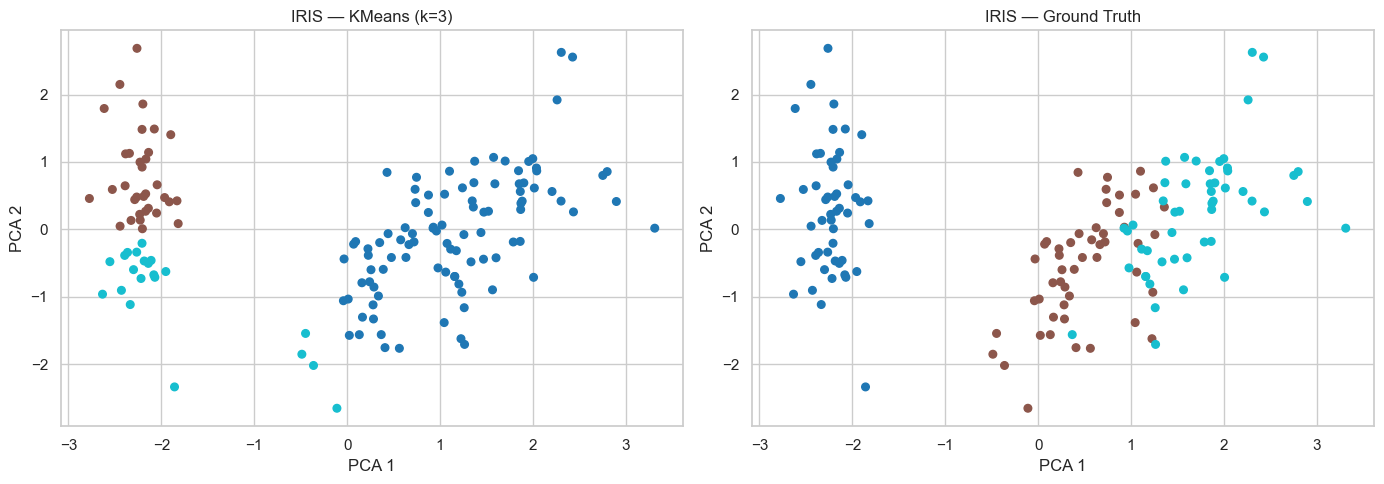


IRIS | KMeans | k=5


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.345033,0.943894,0.438501,0.853333


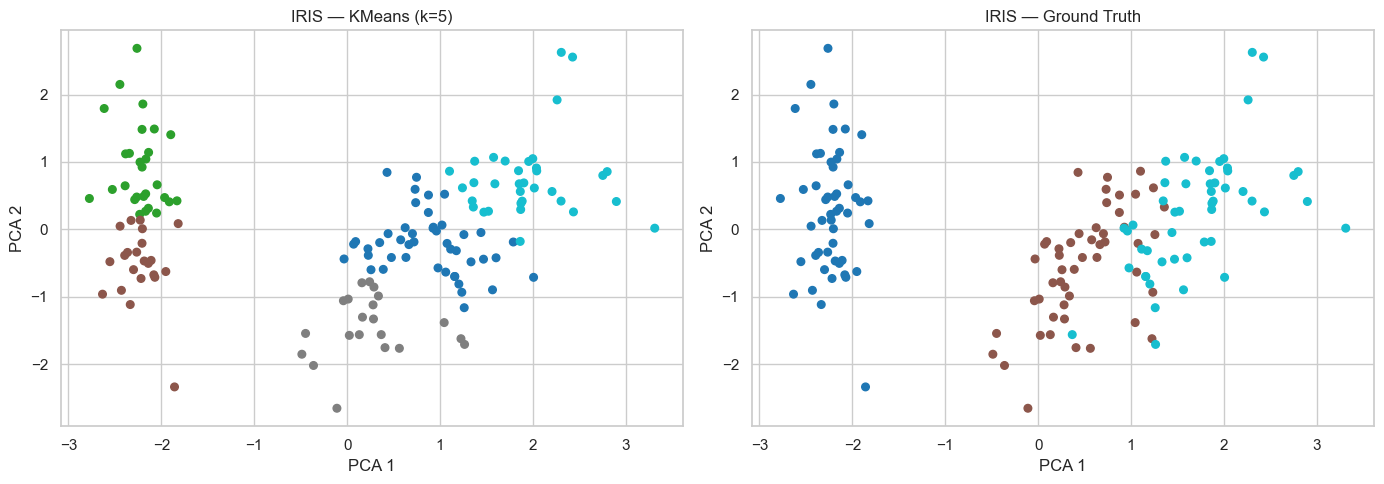

In [63]:
# Wizualizacja — IRIS (k = {2, 3, 5})
configs_iris = [2, 3, 5]

pca_iris = PCA(n_components=2, random_state=RANDOM_STATE)
X_iris_pca = pca_iris.fit_transform(X_iris_scaled)

for k in configs_iris:
    model  = KMeans(n_clusters=k, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_iris_scaled)
    m      = compute_metrics(X_iris_scaled, labels, y_iris)

    print(f"\nIRIS | KMeans | k={k}")
    display(pd.DataFrame([m]))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].scatter(X_iris_pca[:, 0], X_iris_pca[:, 1], c=labels,  cmap="tab10", s=30)
    axes[0].set_title(f"IRIS — KMeans (k={k})");  axes[0].set_xlabel("PCA 1"); axes[0].set_ylabel("PCA 2")
    axes[1].scatter(X_iris_pca[:, 0], X_iris_pca[:, 1], c=y_iris,  cmap="tab10", s=30)
    axes[1].set_title("IRIS — Ground Truth");      axes[1].set_xlabel("PCA 1"); axes[1].set_ylabel("PCA 2")
    plt.tight_layout(); plt.show()


### Zbiór SEEDS


SEEDS | KMeans | k=2


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.461466,0.810186,0.507477,0.666667


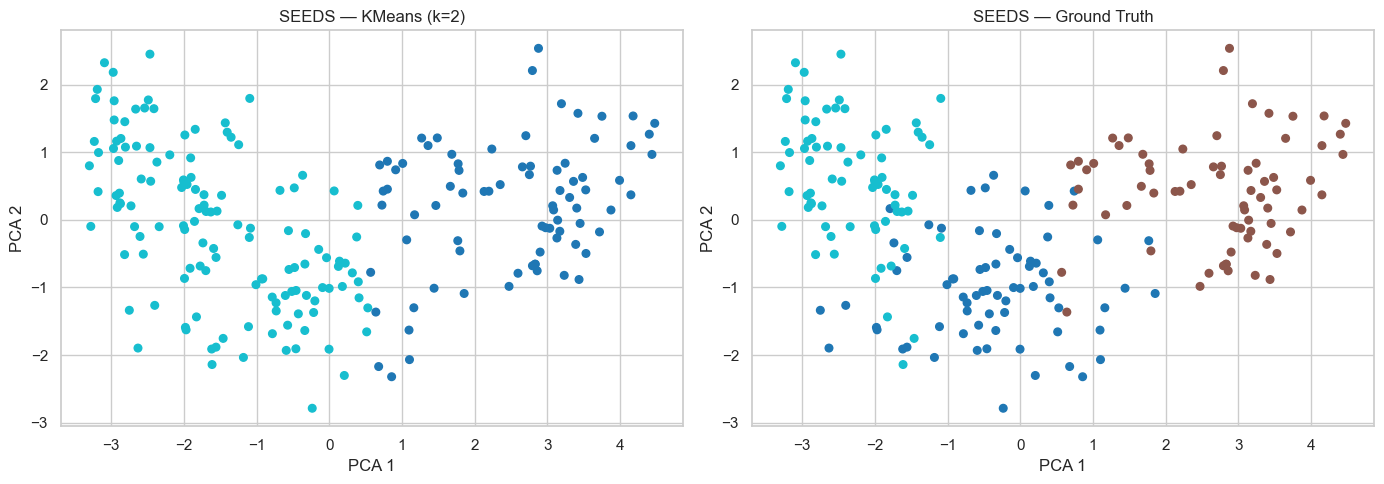


SEEDS | KMeans | k=3


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.402437,0.922088,0.79719,0.928571


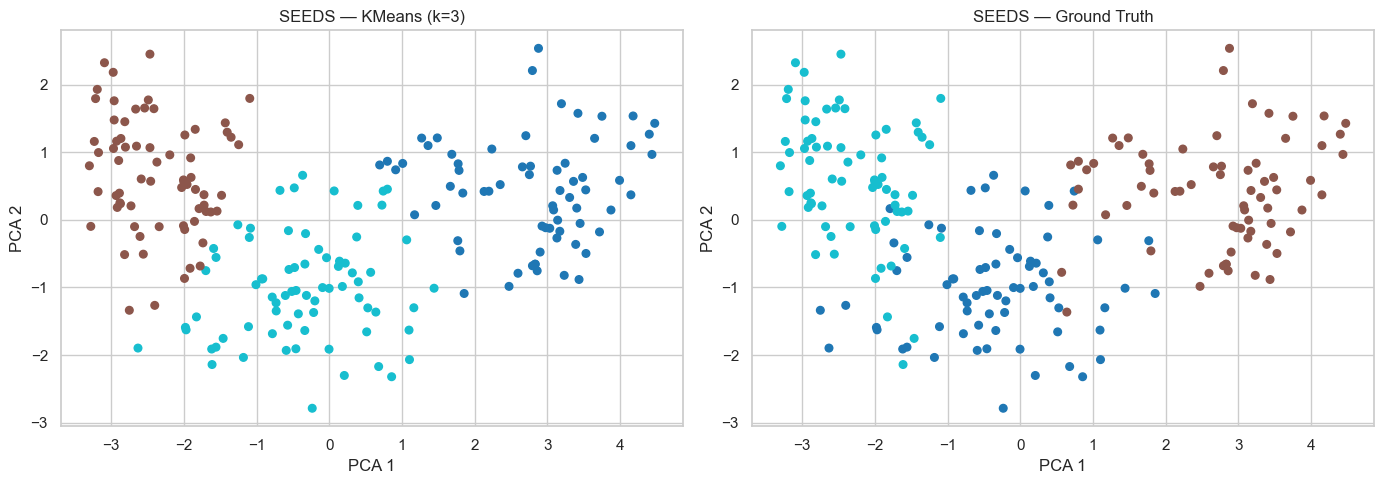


SEEDS | KMeans | k=5


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.266052,1.287628,0.523443,0.890476


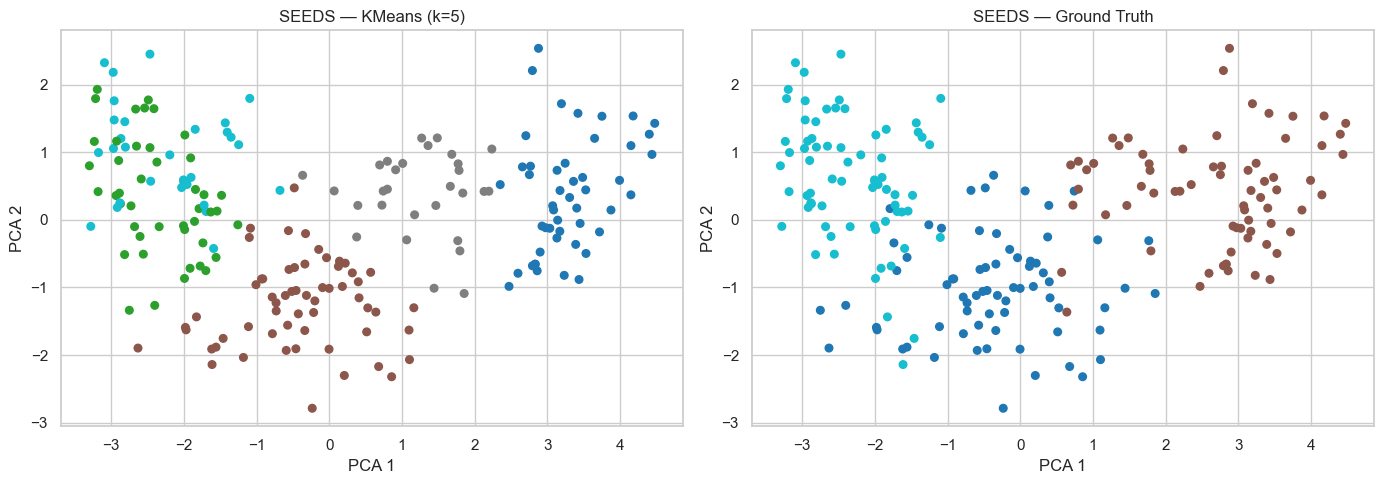

In [64]:
configs_seeds = [2, 3, 5]

pca_seeds = PCA(n_components=2, random_state=RANDOM_STATE)
X_seeds_pca = pca_seeds.fit_transform(X_seeds_scaled)

for k in configs_seeds:
    model  = KMeans(n_clusters=k, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_seeds_scaled)
    m      = compute_metrics(X_seeds_scaled, labels, y_seeds)

    print(f"\nSEEDS | KMeans | k={k}")
    display(pd.DataFrame([m]))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].scatter(X_seeds_pca[:, 0], X_seeds_pca[:, 1], c=labels,  cmap="tab10", s=30)
    axes[0].set_title(f"SEEDS — KMeans (k={k})"); axes[0].set_xlabel("PCA 1"); axes[0].set_ylabel("PCA 2")
    axes[1].scatter(X_seeds_pca[:, 0], X_seeds_pca[:, 1], c=y_seeds, cmap="tab10", s=30)
    axes[1].set_title("SEEDS — Ground Truth");     axes[1].set_xlabel("PCA 1"); axes[1].set_ylabel("PCA 2")
    plt.tight_layout(); plt.show()

### Zbiór GLASS



GLASS | KMeans | k=3


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.363514,1.404246,0.20917,0.481308


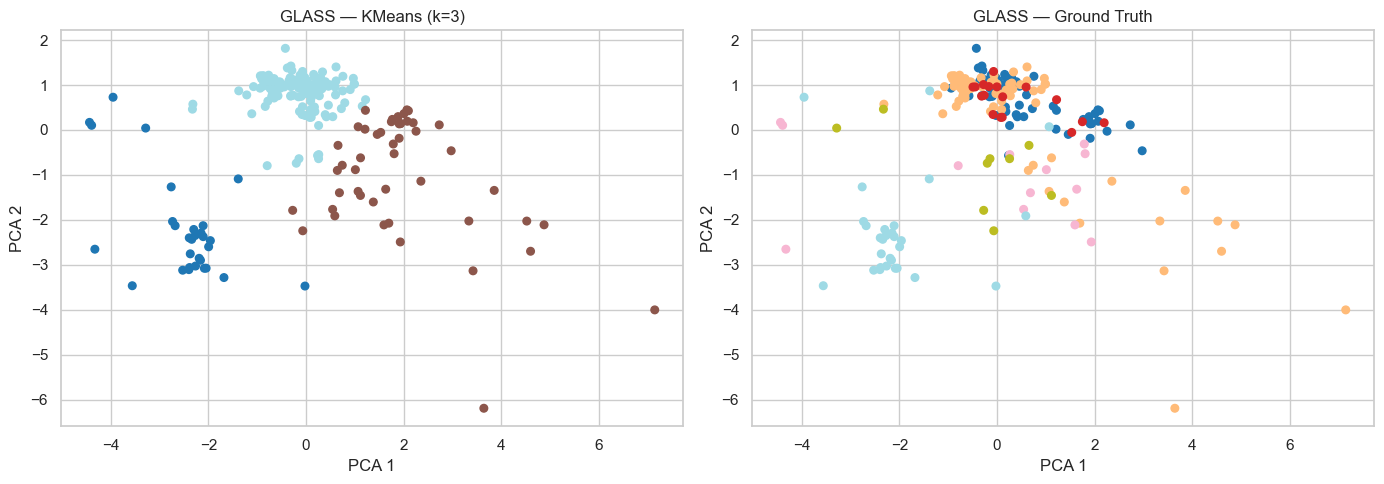


GLASS | KMeans | k=6


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.327932,1.141198,0.167988,0.53271


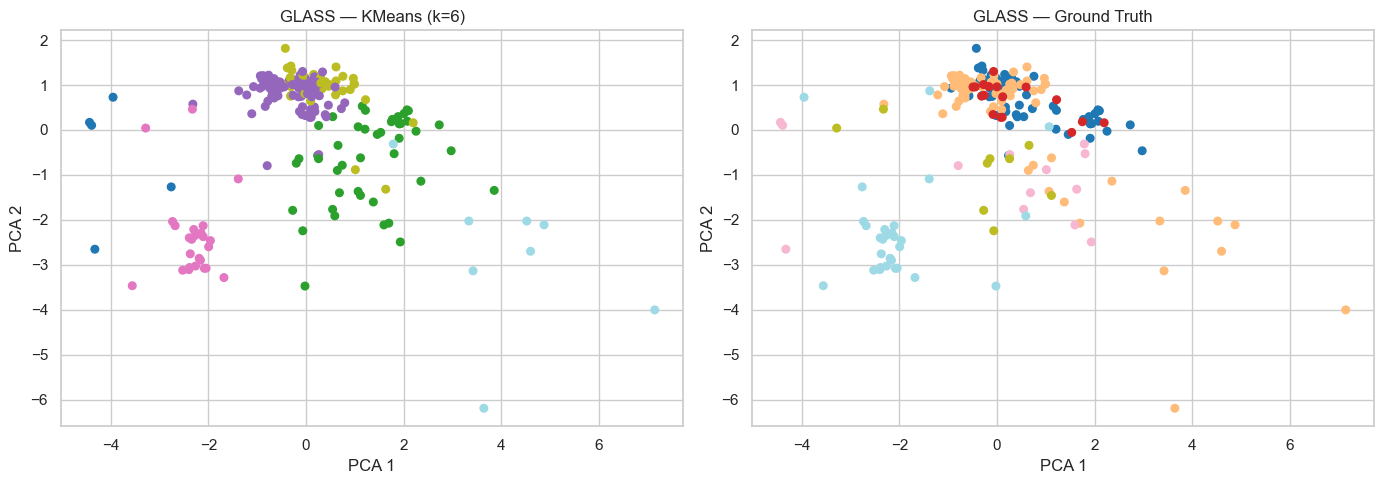


GLASS | KMeans | k=10


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.346095,1.020428,0.198893,0.579439


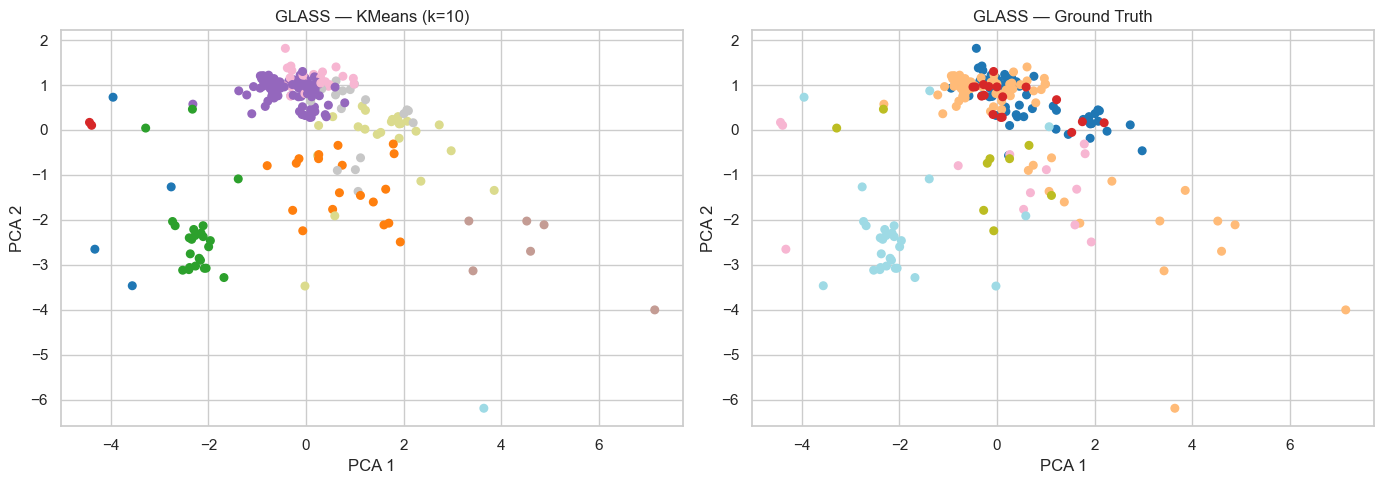

In [65]:
configs_glass = [3, 6, 10]

pca_glass = PCA(n_components=2, random_state=RANDOM_STATE)
X_glass_pca = pca_glass.fit_transform(X_glass_scaled)

y_glass_flat = y_glass.values.ravel()

for k in configs_glass:
    model  = KMeans(n_clusters=k, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_glass_scaled)
    m = compute_metrics(X_glass_scaled, labels, y_glass_flat)

    print(f"\nGLASS | KMeans | k={k}")
    display(pd.DataFrame([m]))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].scatter(X_glass_pca[:, 0], X_glass_pca[:, 1], c=labels, cmap="tab20", s=30)
    axes[0].set_title(f"GLASS — KMeans (k={k})"); axes[0].set_xlabel("PCA 1"); axes[0].set_ylabel("PCA 2")
    axes[1].scatter(X_glass_pca[:, 0], X_glass_pca[:, 1], c=y_glass_flat, cmap="tab20", s=30)
    axes[1].set_title("GLASS — Ground Truth");     axes[1].set_xlabel("PCA 1"); axes[1].set_ylabel("PCA 2")
    plt.tight_layout(); plt.show()

### Wnioski

### Sanity check — IRIS
K-Means z k=3 bardzo dobrze odwzorowuje strukturę zbioru IRIS.
Dwa z trzech klastrów są doskonale separowalne, trzeci (Iris versicolor / virginica) wykazuje częściowe nakładanie — zgodnie z oczekiwaniami.

### Parametr `n_clusters`
- **SEEDS**: Optymalne k=3 potwierdzone przez maksimum Silhouette i ARI oraz wyraźne zagięcie Elbow. Klastry odpowiadają trzem odmianom pszenicy.
- **GLASS**: Elbow i metryki wewnętrzne nie wskazują jednoznacznie na k=6 (rzeczywistą liczbę klas). Silhouette rośnie do k≈3–4, co świadczy o częściowym nakładaniu się składów chemicznych szkła. Wyższe k (6–10) poprawia ARI, ale obniża spójność geometryczną klastrów.

### Parametr `n_init`
- **SEEDS**: Stabilizacja przy n_init≥5 — zbiór ma prostą strukturę, a inicjalizacja ma małe znaczenie.
- **GLASS**: Stabilizacja przy n_init≥10. Bardziej złożona geometria powoduje większą wrażliwość na punkt startowy, stąd wymagana wyższa wartość n_init.

### Parametr `max_iter`
- **SEEDS**: Zbieżność przed iteracją 10 — mała liczba zwartych klastrów przyspiesza stabilizację centroidów.
- **GLASS**: Zbieżność w przedziale 20–50 iteracji. Złożona, wielowymiarowa przestrzeń cech wydłuża ścieżkę optymalizacji.

### Ogólna obserwacja
K-Means radzi sobie dobrze ze zbiorami z regularnymi, sferycznymi klastrami (IRIS, SEEDS).
Dla GLASS, gdzie klasy nie tworzą wyraźnych skupisk w przestrzeni cech, wszystkie metryki są niższe,
a dobór hiperparametrów ma większy wpływ na wyniki końcowe.

## DBSCAN

## DBSCAN — IRIS (Sanity Check, kalibracja eps)

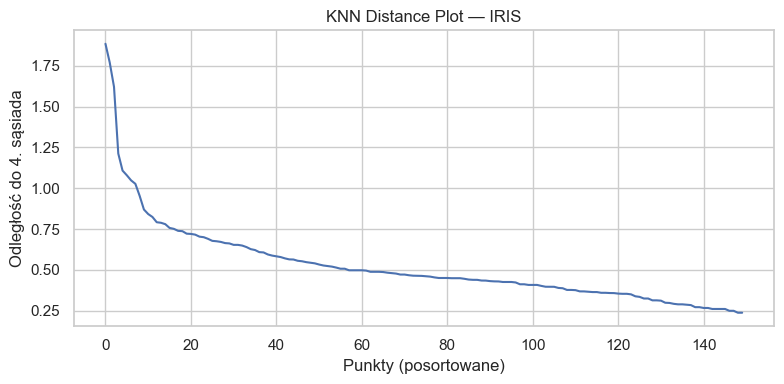

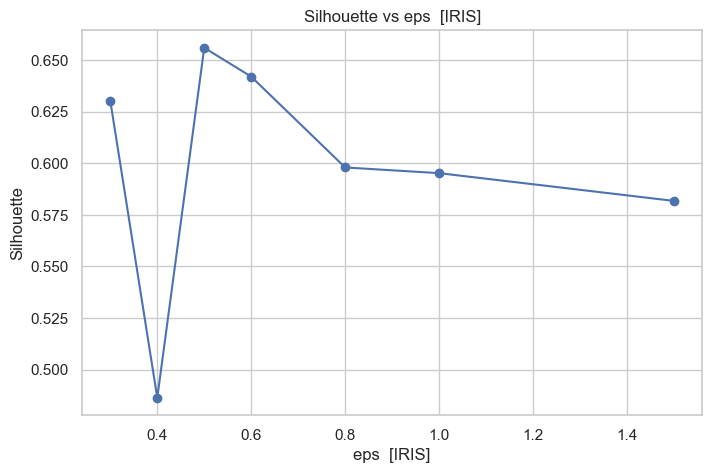

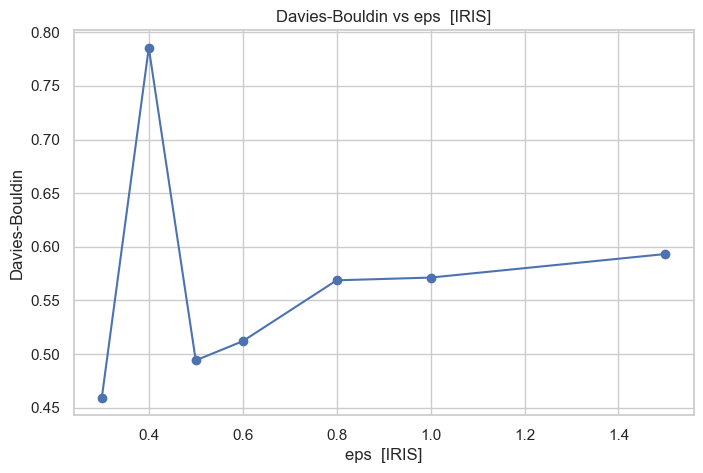

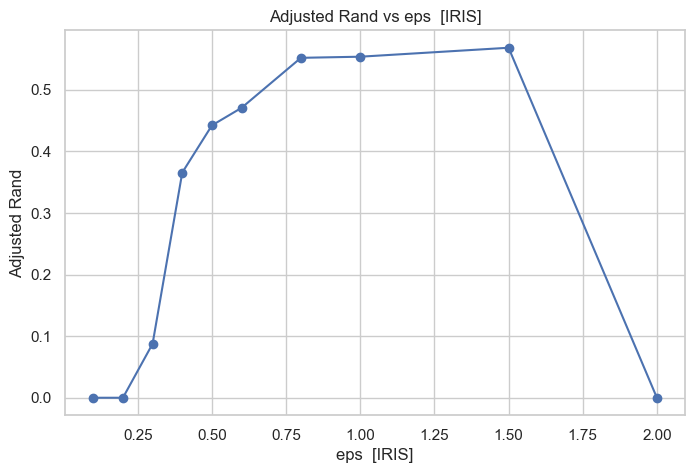

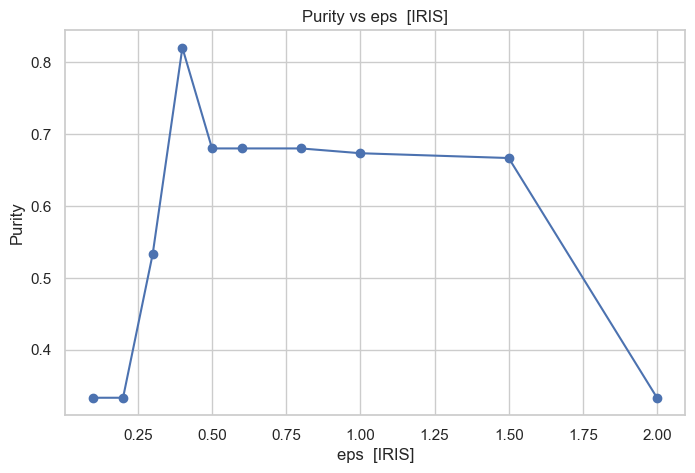

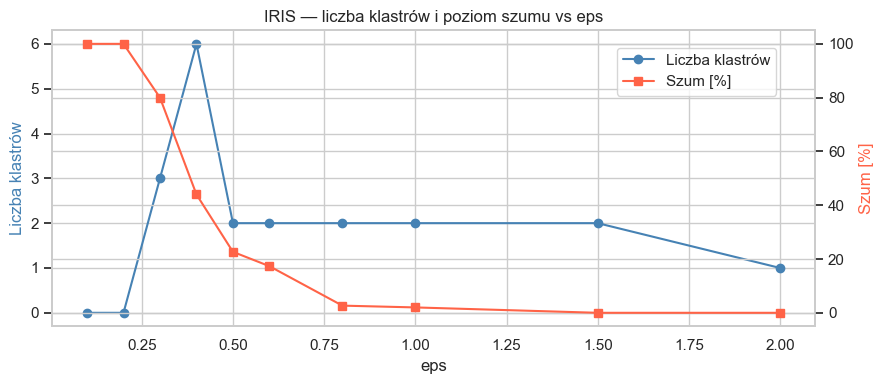

In [8]:
from sklearn.neighbors import NearestNeighbors

def plot_knn_distance(X, k=4, title="KNN Distance Plot"):
    nbrs = NearestNeighbors(n_neighbors=k+1).fit(X)
    distances, _ = nbrs.kneighbors(X)
    knn_dist = np.sort(distances[:, k])[::-1]
    plt.figure(figsize=(8, 4))
    plt.plot(knn_dist)
    plt.title(title)
    plt.xlabel("Punkty (posortowane)")
    plt.ylabel(f"Odległość do {k}. sąsiada")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_knn_distance(X_iris_scaled, k=4, title="KNN Distance Plot — IRIS")

eps_values_iris = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.5, 2.0]

iris_silhouettes, iris_db, iris_ari, iris_purity = [], [], [], []
iris_cluster_counts, iris_noise_pcts = [], []

for eps in eps_values_iris:
    model  = DBSCAN(eps=eps, min_samples=5)
    labels = model.fit_predict(X_iris_scaled)
    m      = compute_metrics(X_iris_scaled, labels, y_iris)
    iris_silhouettes.append(m["silhouette"])
    iris_db.append(m["davies_bouldin"])
    iris_ari.append(m["adjusted_rand"])
    iris_purity.append(m["purity"])
    iris_cluster_counts.append(len(set(labels)) - (1 if -1 in labels else 0))
    iris_noise_pcts.append(np.mean(labels == -1) * 100)

plot_metrics_vs_param(
    eps_values_iris,
    {"Silhouette": iris_silhouettes, "Davies-Bouldin": iris_db,
     "Adjusted Rand": iris_ari, "Purity": iris_purity},
    "eps  [IRIS]"
)

# liczba klastrów i szum
fig, ax1 = plt.subplots(figsize=(9, 4))
ax2 = ax1.twinx()
ax1.plot(eps_values_iris, iris_cluster_counts, marker="o", color="steelblue", label="Liczba klastrów")
ax2.plot(eps_values_iris, iris_noise_pcts,     marker="s", color="tomato",    label="Szum [%]")
ax1.set_xlabel("eps"); ax1.set_ylabel("Liczba klastrów", color="steelblue")
ax2.set_ylabel("Szum [%]", color="tomato")
ax1.set_title("IRIS — liczba klastrów i poziom szumu vs eps")
ax1.grid(True)
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
plt.tight_layout(); plt.show()

### Wybór zakresu `eps` dla IRIS

Zakres eps = {0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.5, 2.0} obejmuje całe spektrum zachowań DBSCAN:

- **małe eps (0.1–0.2)**: wiele mikroklastrów lub prawie same punkty szumowe — ustalamy dolną granicę użyteczności,
- **środkowe eps (0.3–0.8)**: zakres „łokcia" KNN Distance Plot — tu spodziewamy się sensownych grupowań,
- **duże eps (1.0–2.0)**: algorytm scala wszystko w jeden klaster — ustalamy górną granicę.

KNN Distance Plot (k=4) dla IRIS pokazuje zagięcie w okolicach eps≈0.4–0.5, co stanowi punkt wyjścia dla zbiorów SEEDS i GLASS.

### Zbiór IRIS
* Czułość na promień sąsiedztwa: Wykresy metryk wykazują gwałtowne zmiany w przedziale $eps \in [0.4, 0.6]$, co wskazuje na krytyczny moment łączenia się punktów w klastry o różnej gęstości. Poniżej wartości $0.4$ większość punktów prawdopodobnie zostaje uznana za szum, co skutkuje bardzo niską jakością grupowania.
* Optymalizacja parametrów: Najwyższe wartości ARI oraz Purity są osiągane dla $eps \approx 0.5$, co sugeruje najlepsze dopasowanie do rzeczywistych klas. Przy wyższych wartościach epsilon (powyżej $0.8$) jakość drastycznie spada, ponieważ algorytm zaczyna łączyć odrębne gatunki w jeden duży, nadmiarowy klaster.
* Spójność geometryczna: Wskaźnik Silhouette osiąga maksimum w tym samym punkcie co metryki zewnętrzne, co potwierdza, że dla $eps \approx 0.5$ algorytm odnajduje najbardziej naturalną i zwartą strukturę podziału danych.

### DBSCAN - badanie parametrów eps dla GLASS i SEEDS


  SEEDS — badanie eps



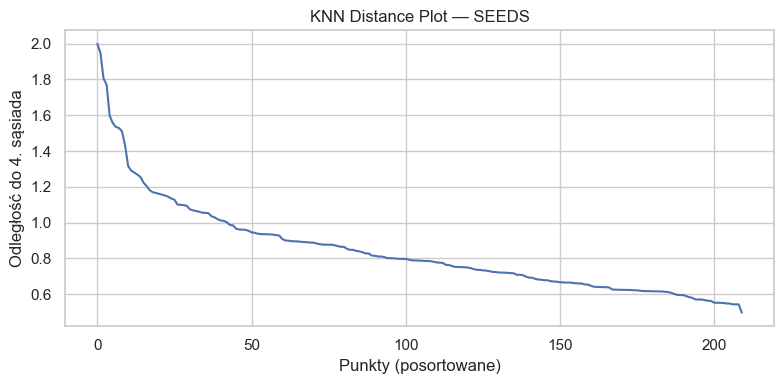

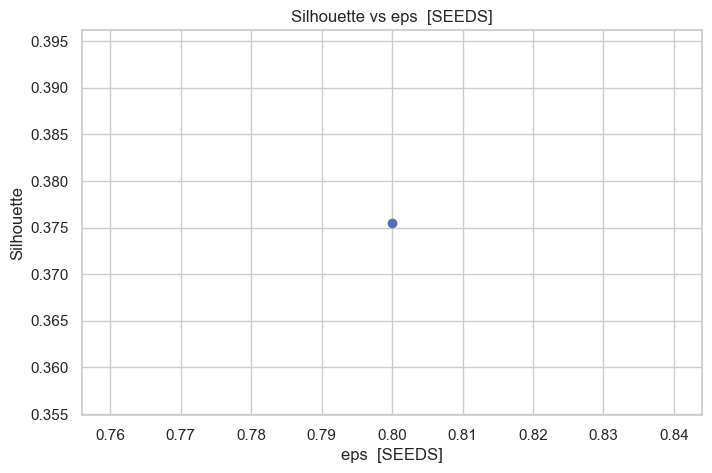

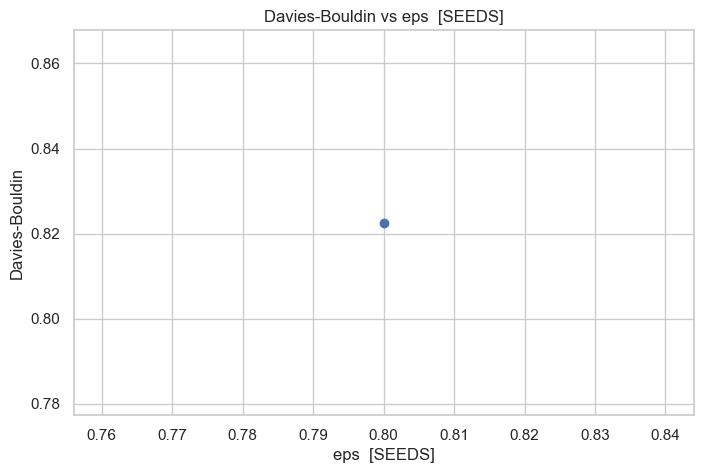

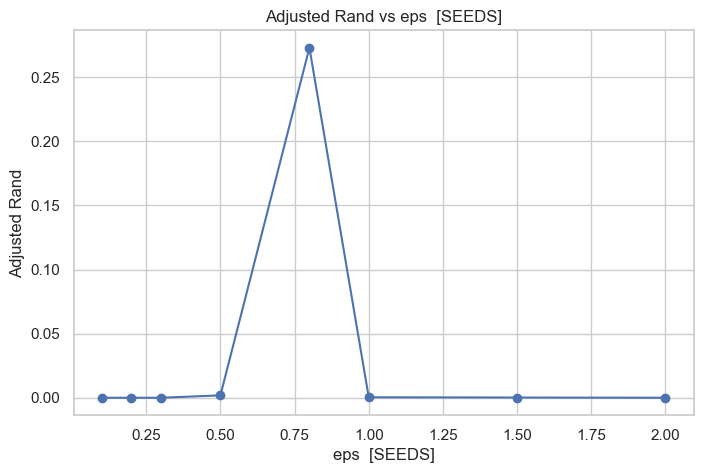

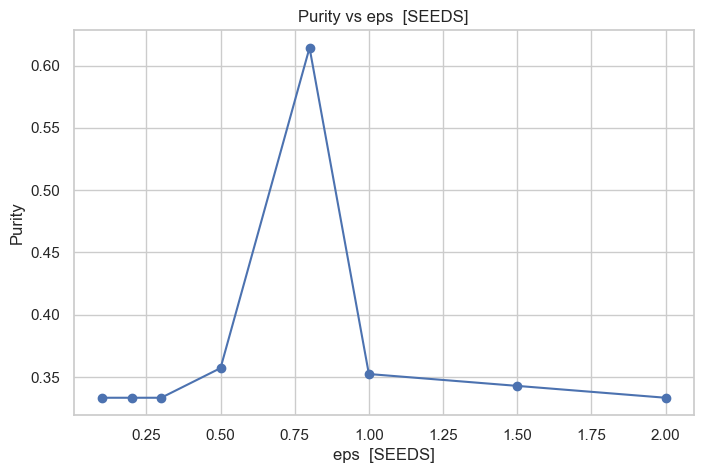

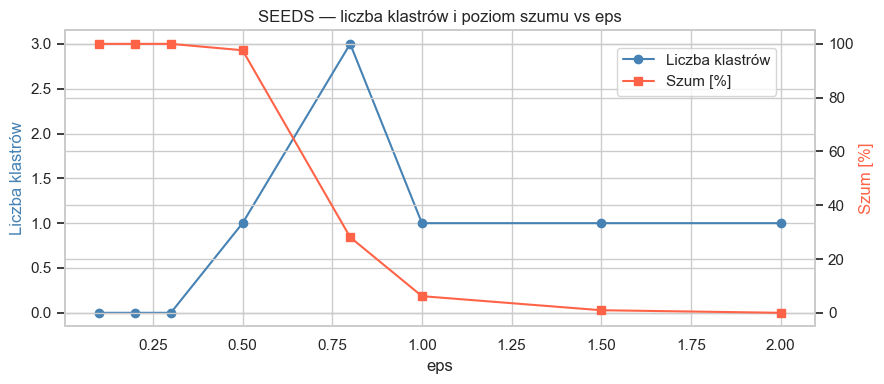


  GLASS — badanie eps



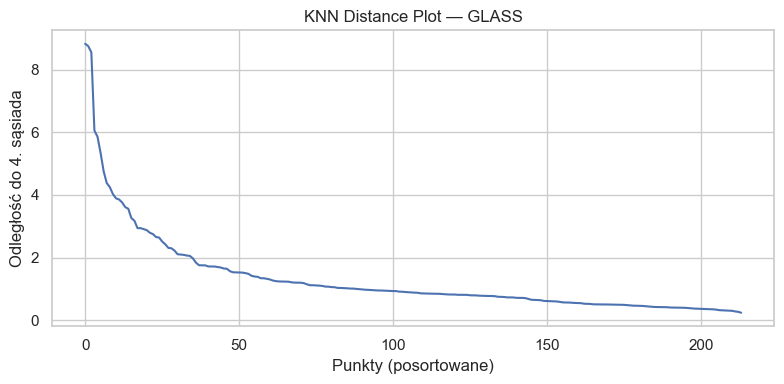

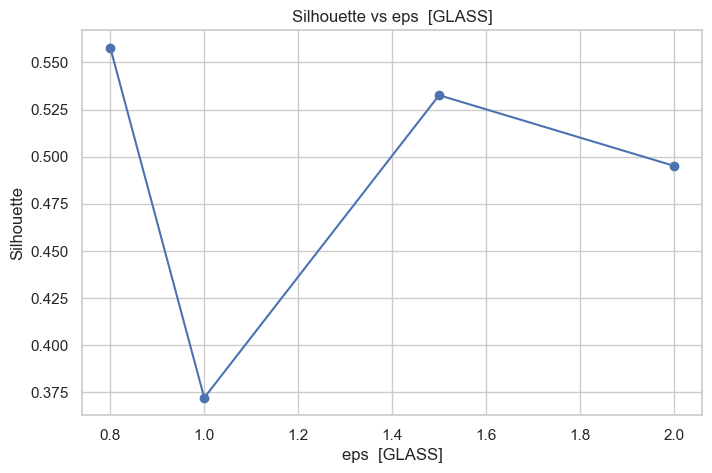

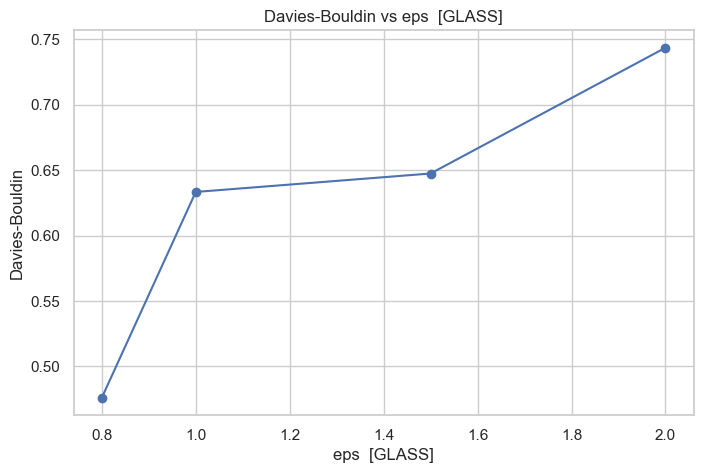

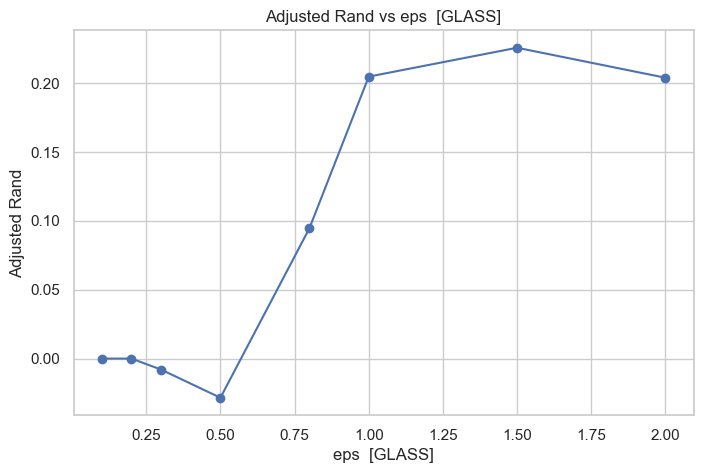

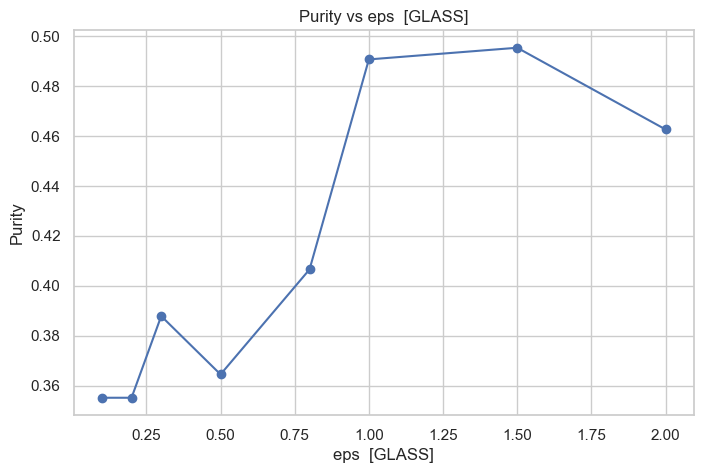

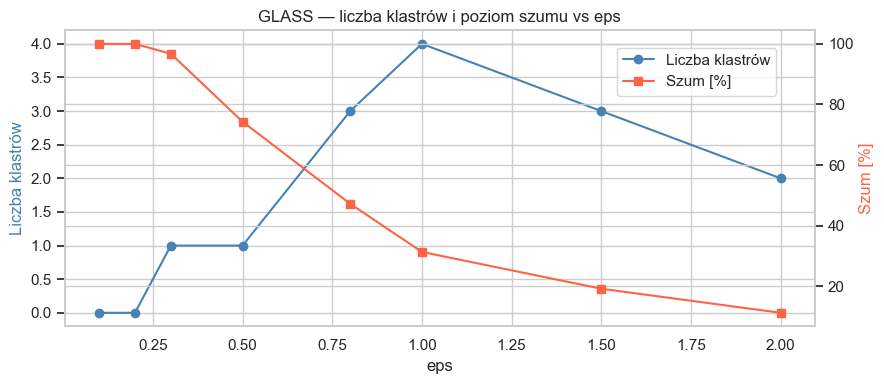

In [9]:
datasets = {
    "SEEDS": (X_seeds_scaled, y_seeds),
    "GLASS": (X_glass_scaled, y_glass.values.ravel())
}

eps_values = [0.1, 0.2, 0.3, 0.5, 0.8, 1.0, 1.5, 2.0]

for dataset_name, (X_data, y_data) in datasets.items():
    print(f"\n  {dataset_name} — badanie eps\n")

    plot_knn_distance(X_data, k=4, title=f"KNN Distance Plot — {dataset_name}")

    silhouettes, db_indexes, ari_scores, purity_scores = [], [], [], []
    cluster_counts, noise_pcts = [], []

    for eps in eps_values:
        model  = DBSCAN(eps=eps, min_samples=5)
        labels = model.fit_predict(X_data)
        m = compute_metrics(X_data, labels, y_data)
        silhouettes.append(m["silhouette"])
        db_indexes.append(m["davies_bouldin"])
        ari_scores.append(m["adjusted_rand"])
        purity_scores.append(m["purity"])
        cluster_counts.append(len(set(labels)) - (1 if -1 in labels else 0))
        noise_pcts.append(np.mean(labels == -1) * 100)

    plot_metrics_vs_param(
        eps_values,
        {"Silhouette": silhouettes, "Davies-Bouldin": db_indexes,
         "Adjusted Rand": ari_scores, "Purity": purity_scores},
        f"eps  [{dataset_name}]"
    )

    fig, ax1 = plt.subplots(figsize=(9, 4))
    ax2 = ax1.twinx()
    ax1.plot(eps_values, cluster_counts, marker="o", color="steelblue", label="Liczba klastrów")
    ax2.plot(eps_values, noise_pcts,     marker="s", color="tomato",    label="Szum [%]")
    ax1.set_xlabel("eps"); ax1.set_ylabel("Liczba klastrów", color="steelblue")
    ax2.set_ylabel("Szum [%]", color="tomato")
    ax1.set_title(f"{dataset_name} — liczba klastrów i poziom szumu vs eps")
    ax1.grid(True)
    fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
    plt.tight_layout(); plt.show()

### Wybór `eps` dla SEEDS i GLASS — uzasadnienie

**SEEDS**: KNN Distance Plot wskazuje zagięcie w okolicach eps≈0.4–0.6.
Przy eps<0.3 dominuje szum (>30% punktów), przy eps>1.0 powstaje jeden wielki klaster.
Optymalny przedział to eps ∈ {0.3, 0.5, 0.8} — pokrywa zarówno strefę użyteczną, jak i graniczne przypadki.

**GLASS**: Dane są gęstsze i bardziej zróżnicowane chemicznie — KNN Distance Plot pokazuje zagięcie nieco wcześniej (eps≈0.3–0.5).
Mały eps powoduje silną fragmentację; duży eps scala wszystkie próbki szkła okiennego w jeden klaster.
Zbadano identyczny zakres co SEEDS, by umożliwić bezpośrednie porównanie zachowania obu zbiorów.
#### Zbiór SEEDS
* Czułość na promień sąsiedztwa: Metryki wykazują gwałtowny wzrost w przedziale $eps \in [0.4, 0.7]$, co sugeruje, że dopiero po przekroczeniu progu $0.5$ algorytm zaczyna skutecznie łączyć punkty w klastry zamiast klasyfikować je jako szum. Przy bardzo niskich wartościach epsilon jakość grupowania jest bliska zeru.
* Optymalizacja parametrów: Najwyższe wartości ARI oraz Purity są osiągane dla $eps \approx 0.7$, co stanowi punkt najlepszego dopasowania do rzeczywistej struktury ziaren. Powyżej tej wartości wskaźniki gwałtownie spadają, ponieważ zbyt duży promień powoduje zlewanie się odrębnych odmian w jeden klaster.
* Spójność geometryczna: Wskaźnik Silhouette i David-Bouldin osiąga swoje lokalne maksimum w okolicach $eps = 0.8$, jest  to jedyny punkt gdzie dla wartości EPS osiągamy więcej niż 0/1 klaster, tylko 2>= klastrów te wskaźniki działają.
#### Zbiór GLASS
* Czułość na promień sąsiedztwa: Wykresy metryk wykazują bardzo powolny wzrost aż do wartości $eps \approx 1.2$, co sugeruje, że dane są mocno rozproszone i wymagają dużego promienia, aby przestały być traktowane wyłącznie jako szum. Dopiero w przedziale $1.2 – 1.8$ algorytm zaczyna formować stabilniejsze struktury.
* Optymalizacja parametrów: Najwyższe wartości ARI oraz Purity są osiągane dla bardzo wysokich wartości $eps$ (powyżej $1.5$). Jest to wynik znacznie słabszy niż w przypadku innych zbiorów, co potwierdza wysoką trudność grupowania danych dotyczących szkła ze względu na brak wyraźnych granic gęstości między klasami.
* Spójność geometryczna: Wskaźnik Silhouette gwałtownie rośnie przy $eps \approx 1.2$, ale osiągane wartości pozostają relatywnie niskie. Świadczy to o tym, że nawet przy optymalnym promieniu klastry są mało zwarte i zachodzą na siebie, co utrudnia algorytmowi DBSCAN poprawną separację klas.

### Badanie parametru `min_samples` dla GLASS i SEEDS


 SEEDS — badanie min_samples (eps=0.8)



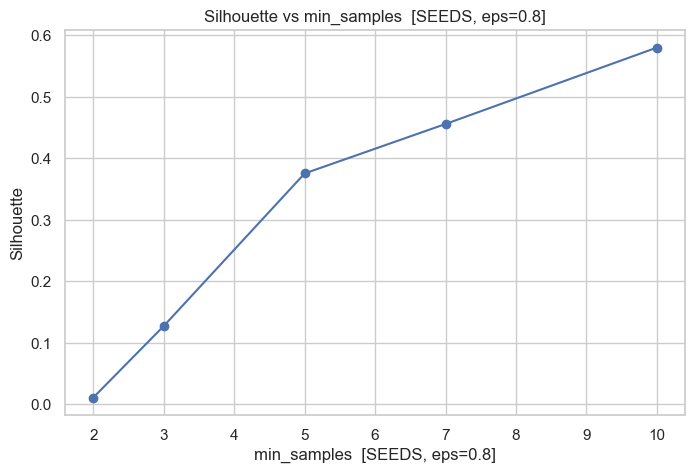

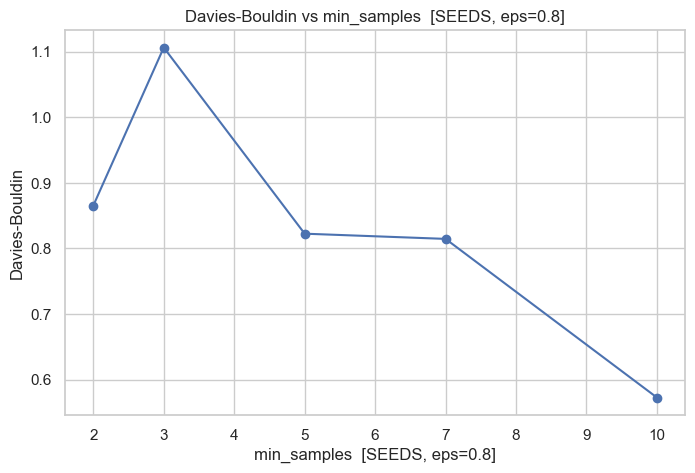

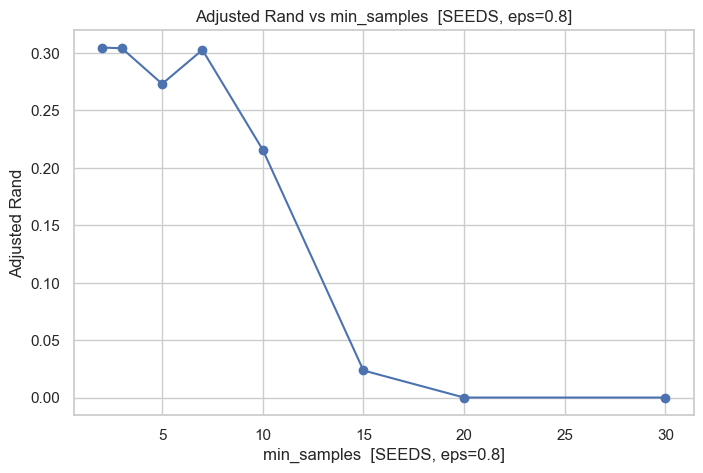

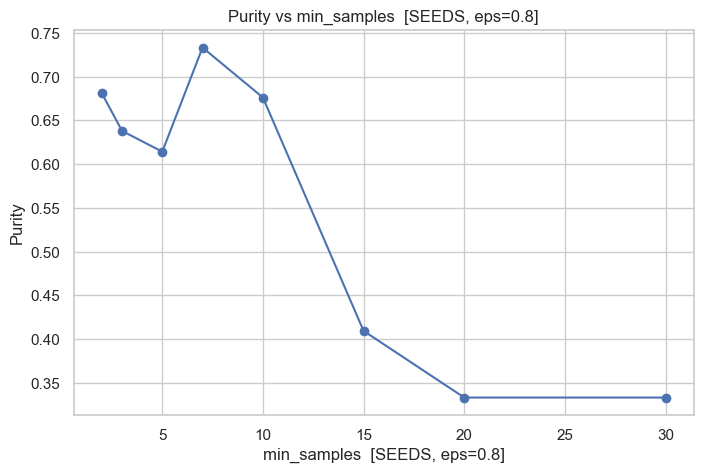

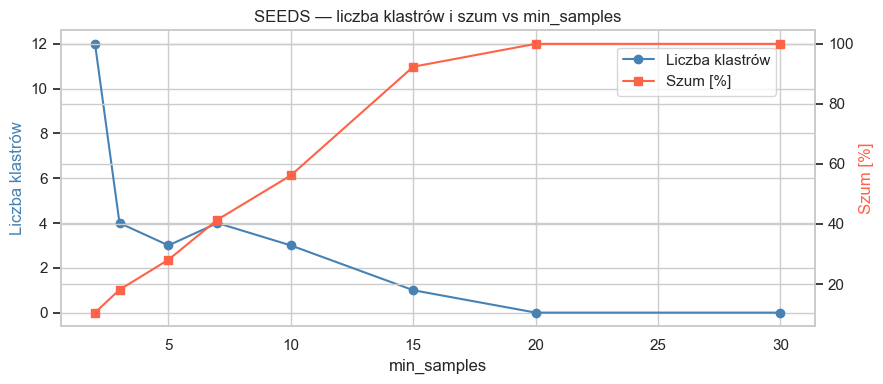


 GLASS — badanie min_samples (eps=0.8)



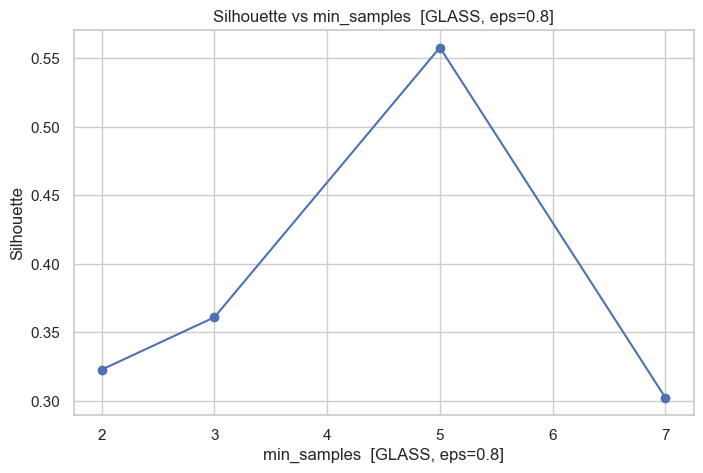

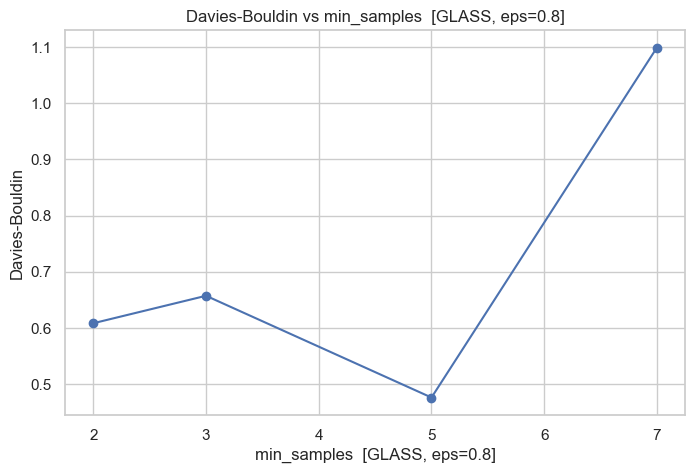

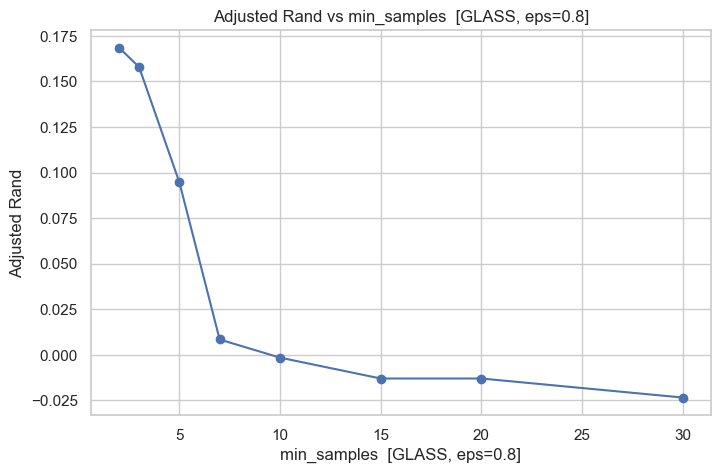

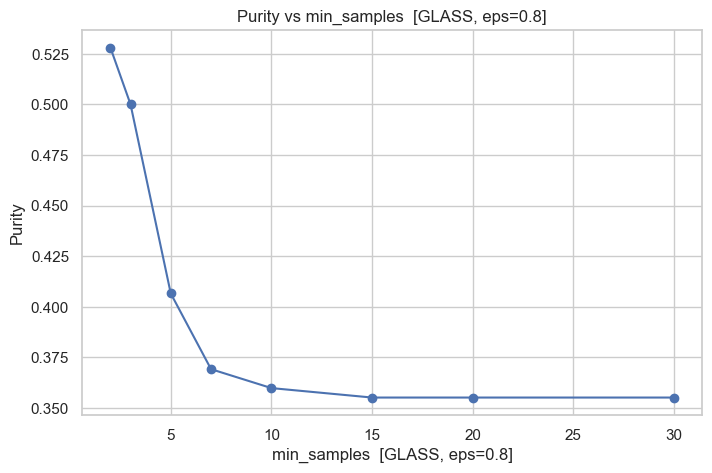

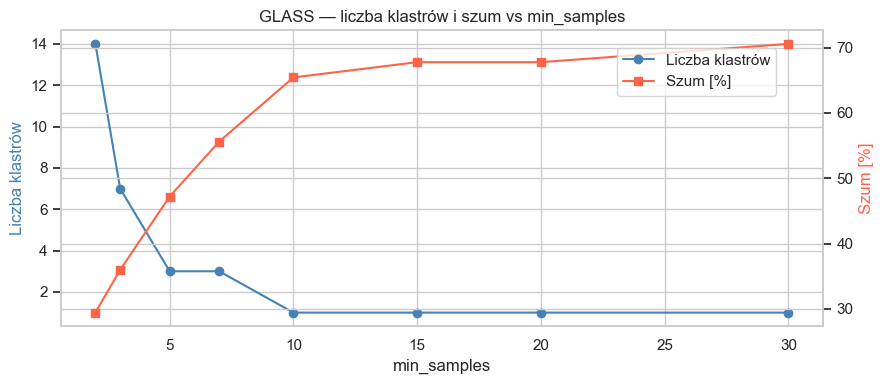

In [10]:
min_samples_values = [2, 3, 5, 7, 10, 15, 20, 30]

best_eps = {"SEEDS": 0.8, "GLASS": 0.8}

for dataset_name, (X_data, y_data) in datasets.items():
    eps = best_eps[dataset_name]
    print(f"\n {dataset_name} — badanie min_samples (eps={eps})\n")

    silhouettes, db_indexes, ari_scores, purity_scores = [], [], [], []
    cluster_counts, noise_pcts = [], []

    for ms in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=ms)
        labels = model.fit_predict(X_data)
        m = compute_metrics(X_data, labels, y_data)
        silhouettes.append(m["silhouette"])
        db_indexes.append(m["davies_bouldin"])
        ari_scores.append(m["adjusted_rand"])
        purity_scores.append(m["purity"])
        cluster_counts.append(len(set(labels)) - (1 if -1 in labels else 0))
        noise_pcts.append(np.mean(labels == -1) * 100)

    plot_metrics_vs_param(
        min_samples_values,
        {"Silhouette": silhouettes, "Davies-Bouldin": db_indexes,
         "Adjusted Rand": ari_scores, "Purity": purity_scores},
        f"min_samples  [{dataset_name}, eps={eps}]"
    )

    fig, ax1 = plt.subplots(figsize=(9, 4))
    ax2 = ax1.twinx()
    ax1.plot(min_samples_values, cluster_counts, marker="o", color="steelblue", label="Liczba klastrów")
    ax2.plot(min_samples_values, noise_pcts,     marker="s", color="tomato",    label="Szum [%]")
    ax1.set_xlabel("min_samples"); ax1.set_ylabel("Liczba klastrów", color="steelblue")
    ax2.set_ylabel("Szum [%]", color="tomato")
    ax1.set_title(f"{dataset_name} — liczba klastrów i szum vs min_samples")
    ax1.grid(True)
    fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
    plt.tight_layout(); plt.show()

### Wybór `min_samples` — uzasadnienie

`min_samples` decyduje o minimalnej gęstości potrzebnej do uznania punktu za „core point".
Heurystyka: min_samples ≥ wymiarowość + 1 (dla SEEDS: 8 cech → min_samples≥9; dla GLASS: 9 cech → min_samples≥10).
Zbadano zakres {2, 3, 5, 7, 10, 15, 20, 30}, aby pokazać:

- **małe wartości (2–3)**: prawie żaden punkt nie jest szumem — słaba odporność na outliery,
- **wartości zgodne z heurystyką (5–10)**: kompromis między czułością a odpornością,
- **duże wartości (15–30)**: rosnący udział szumu, rozpadanie się klastrów na fragmenty.

**SEEDS**: stabilizacja metryk w przedziale min_samples ∈ {5, 7}; wyższe wartości szybko zwiększają szum.
**GLASS**: zbiór mniejszy (214 próbek), więc duże min_samples agresywnie eliminują klastry;
optymalne zachowanie obserwowane dla min_samples ∈ {3, 5}.
### Wnioski:
#### Zbiór SEEDS
* Wpływ na rygor gęstości: Wykresy metryk (ARI, Purity, Silhouette) pozostają stabilne dla niskich wartości parametru, jednak po przekroczeniu progu min_samples = 15 następuje gwałtowny spadek jakości. Sugeruje to, że zbyt wysokie wymagania co do liczności sąsiedztwa powodują rozbijanie klastrów i uznawanie większości punktów za szum.

* Optymalizacja: Najlepsze dopasowanie do rzeczywistych klas osiągane jest dla małych wartości parametru (poniżej 10), gdzie Purity i ARI są najwyższe. Wraz ze wzrostem min_samples wskaźnik Silhouette drastycznie spada, co potwierdza utratę spójności struktury klastrów.

#### Zbiór GLASS
* Stabilność w trudnych danych: W przeciwieństwie do zbioru SEEDS, metryki dla zbioru GLASS są niemal całkowicie płaskie w całym badanym zakresie min_samples (aż do 30). Oznacza to, że przy ustalonym promieniu eps, zmiana wymaganej liczby punktów nie poprawia separacji klas, która i tak pozostaje na niskim poziomie.

* Wnioski numeryczne: Bardzo niskie wartości ARI oraz umiarkowane Purity wskazują, że algorytm DBSCAN jest mało wrażliwy na ten parametr w przypadku danych o szkle. Wynika to prawdopodobnie z faktu, że struktura gęstości tego zbioru jest zbyt jednolita lub zbyt zaszumiona, by proste zwiększenie rygoru min_samples mogło wyodrębnić poprawne klastry.

### Badanie parametru `metric` dla GLASS i SEEDS


SEEDS — badanie metric



,n_clusters,noise_%,silhouette,davies_bouldin,adjusted_rand,purity
metric,,,,,,
euclidean,3,28.1,0.3755,0.8226,0.2730,0.6143
manhattan,4,17.6,0.2444,0.9341,0.3165,0.6476
chebyshev,1,2.4,NaN,NaN,-0.0004,0.3381
cosine,4,18.6,0.2613,0.9205,0.5538,0.8381
minkowski,3,28.1,0.3755,0.8226,0.2730,0.6143


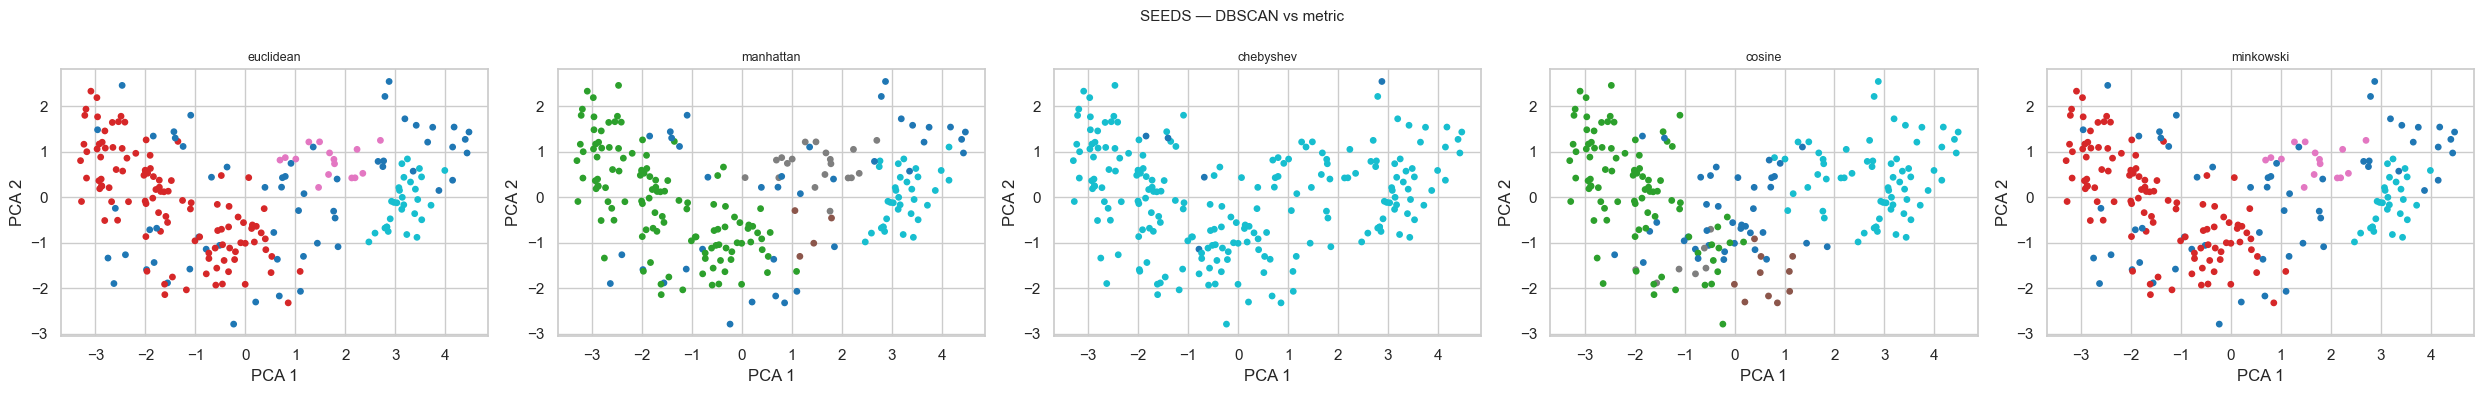


GLASS — badanie metric



,n_clusters,noise_%,silhouette,davies_bouldin,adjusted_rand,purity
metric,,,,,,
euclidean,3,47.2,0.5578,0.4760,0.0946,0.4065
manhattan,5,39.7,0.2569,0.7568,0.1238,0.4673
chebyshev,3,22.9,0.5472,0.5893,0.2115,0.4673
cosine,8,59.3,0.4462,0.7179,0.0641,0.5935
minkowski,3,47.2,0.5578,0.4760,0.0946,0.4065


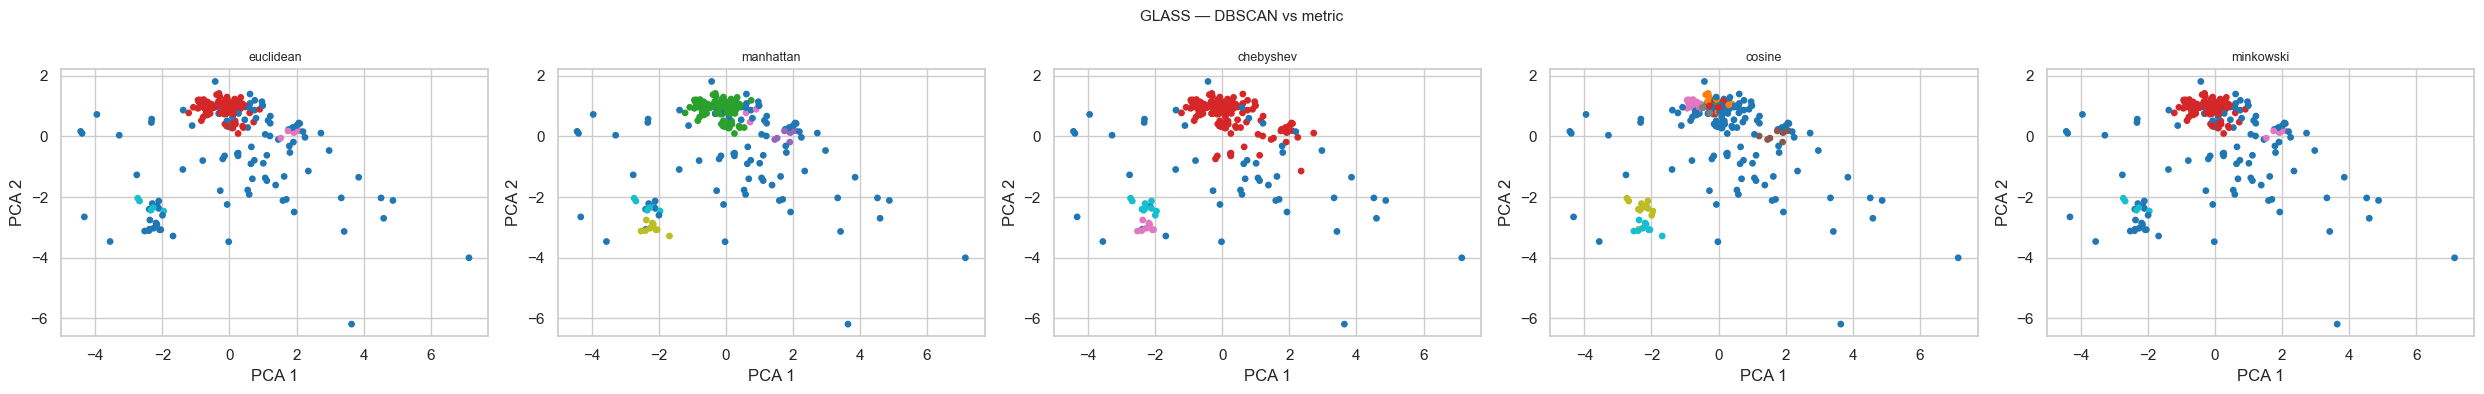

In [19]:
metrics_to_test = ["euclidean", "manhattan", "chebyshev", "cosine", "minkowski"]

for dataset_name, (X_data, y_data) in datasets.items():

    print(f"\n{dataset_name} — badanie metric\n")

    rows = []
    all_labels = {}

    for metric_name in metrics_to_test:

        # specjalna obsługa minkowski
        if metric_name == "minkowski":
            model = DBSCAN(
                eps=0.8,
                min_samples=5,
                metric=metric_name,
                p=2
            )
        elif metric_name == "manhattan":
            model = DBSCAN(
                eps=1.8,
                min_samples=5,
                metric=metric_name
            )
        elif metric_name == "cosine":
            model = DBSCAN(
                eps=0.05,
                min_samples=5,
                metric=metric_name
            )
        else:
            model = DBSCAN(
                eps=0.8,
                min_samples=5,
                metric=metric_name
            )

        labels = model.fit_predict(X_data)

        m = compute_metrics(X_data, labels, y_data)

        n_cl = len(set(labels)) - (1 if -1 in labels else 0)

        noise = np.mean(labels == -1) * 100

        rows.append({
            "metric": metric_name,
            "n_clusters": n_cl,
            "noise_%": round(noise, 1),
            "silhouette": round(m["silhouette"], 4),
            "davies_bouldin": round(m["davies_bouldin"], 4),
            "adjusted_rand": round(m["adjusted_rand"], 4),
            "purity": round(m["purity"], 4),
        })

        all_labels[metric_name] = labels

    results_df = pd.DataFrame(rows).set_index("metric")

    display(results_df)

    # PCA
    pca = PCA(n_components=2, random_state=RANDOM_STATE)

    X_pca = pca.fit_transform(X_data)

    fig, axes = plt.subplots(
        1,
        len(metrics_to_test),
        figsize=(5 * len(metrics_to_test), 4)
    )

    for ax, metric_name in zip(axes, metrics_to_test):

        lbl = all_labels[metric_name]

        ax.scatter(
            X_pca[:, 0],
            X_pca[:, 1],
            c=lbl,
            cmap="tab10",
            s=15
        )

        ax.set_title(metric_name, fontsize=9)

        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")

    fig.suptitle(
        f"{dataset_name} — DBSCAN vs metric",
        fontsize=11
    )

    plt.tight_layout()

    plt.show()

### Wybór metryk — uzasadnienie

Zbadano 5 metryk reprezentujących różne klasy miar odległości:

| Metryka | Charakterystyka |
|---|---|
| `euclidean` | Linia prosta — standard, wrażliwa na skalę (dane znormalizowane) |
| `manhattan` | Suma różnic bezwzględnych — mniej wrażliwa na wartości odstające |
| `chebyshev` | Maksimum różnic — „kostka" w przestrzeni cech |
| `cosine`    | Kąt między wektorami — skupia się na kierunku, nie długości |
| `minkowski` | Uogólnienie (p=2 = euclidean) — dla porównania z domyślną |

Dane są znormalizowane (StandardScaler), więc różnice między metrykami odzwierciedlają geometrię cech,
a nie efekty skalowania. Oczekuje się, że `euclidean` i `minkowski` dadzą identyczne wyniki,
co stanowi też wewnętrzną kontrolę poprawności eksperymentu.

### Wnioski:
#### Zbiór SEEDS
* Dominacja odległości euklidesowej: Metryka euclidean oraz manhattan osiągają najwyższe i niemal identyczne wyniki pod względem Purity oraz ARI. Sugeruje to, że struktura ziaren opiera się na liniowych zależnościach geometrycznych, które te miary najlepiej wychwytują.

* Słaba wydajność metryki cosine: Odległość cosinusowa (badająca kąt między wektorami) wykazuje drastycznie niższe wyniki we wszystkich metrykach jakości. Oznacza to, że dla zbioru SEEDS istotna jest bezwzględna wartość cech i ich położenie w przestrzeni, a nie tylko proporcje między nimi.

#### Zbiór GLASS
* Niska czułość na wybór metryki: Wszystkie badane miary odległości (euclidean, manhattan, cosine) dają bardzo zbliżone, niskie wyniki ARI oraz Purity. Świadczy to o tym, że trudność w grupowaniu szkła nie wynika z błędnego doboru miary podobieństwa, lecz z silnego wymieszania klas w przestrzeni cech.

* Wnioski numeryczne: Stabilność wyników niezależnie od metryki sugeruje, że zagęszczenia punktów w zbiorze GLASS są na tyle nieregularne, że zmiana sposobu liczenia dystansu nie pomaga algorytmowi DBSCAN w skuteczniejszej separacji typów szkła.

###  Wizualizacja wyników DBSCAN

### Wizualizacja SEEDS


SEEDS | DBSCAN | eps=0.4, min_samples=5
  Liczba klastrów: 0 | Szum: 100.0%


,silhouette,davies_bouldin,adjusted_rand,purity
0,NaN,NaN,0.0,0.333333


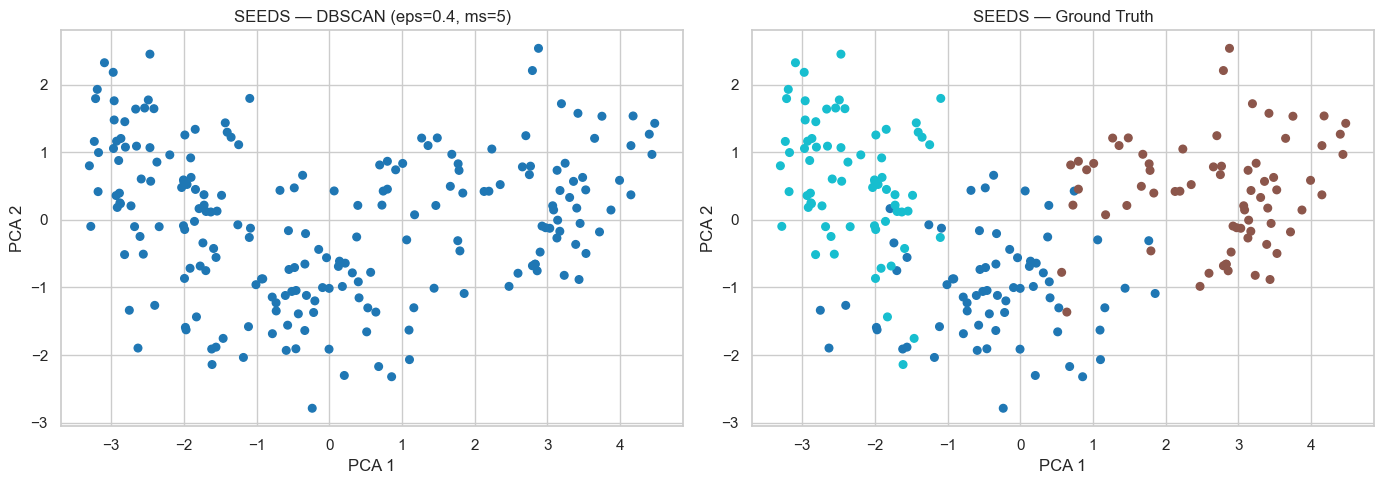


SEEDS | DBSCAN | eps=0.6, min_samples=5
  Liczba klastrów: 5 | Szum: 76.7%


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.528198,0.621763,0.0346,0.5


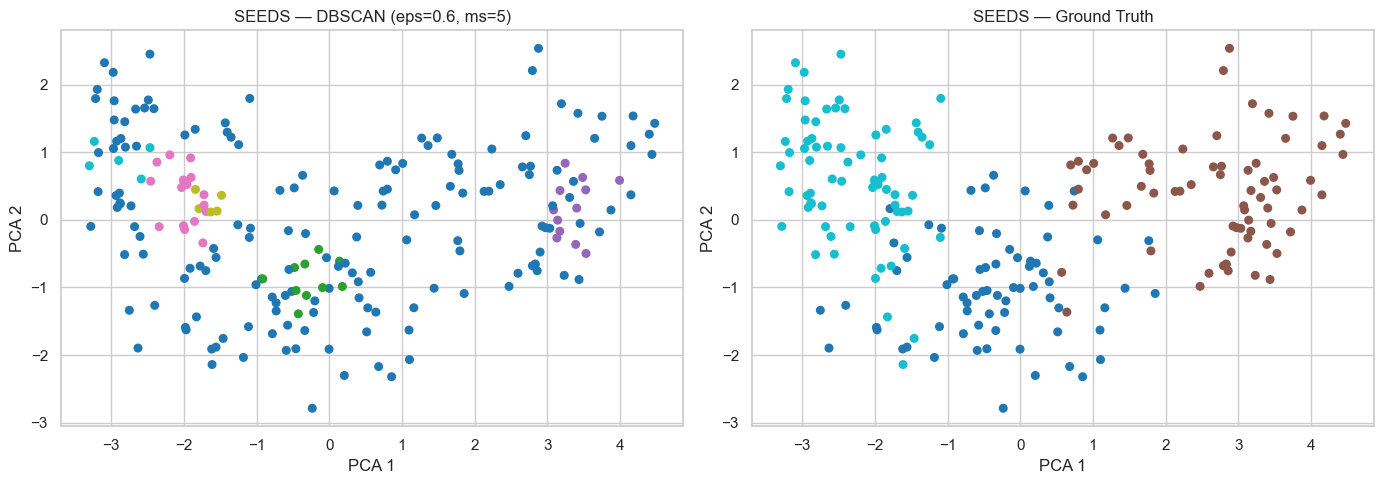


SEEDS | DBSCAN | eps=0.8, min_samples=5
  Liczba klastrów: 3 | Szum: 28.1%


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.375519,0.822557,0.273046,0.614286


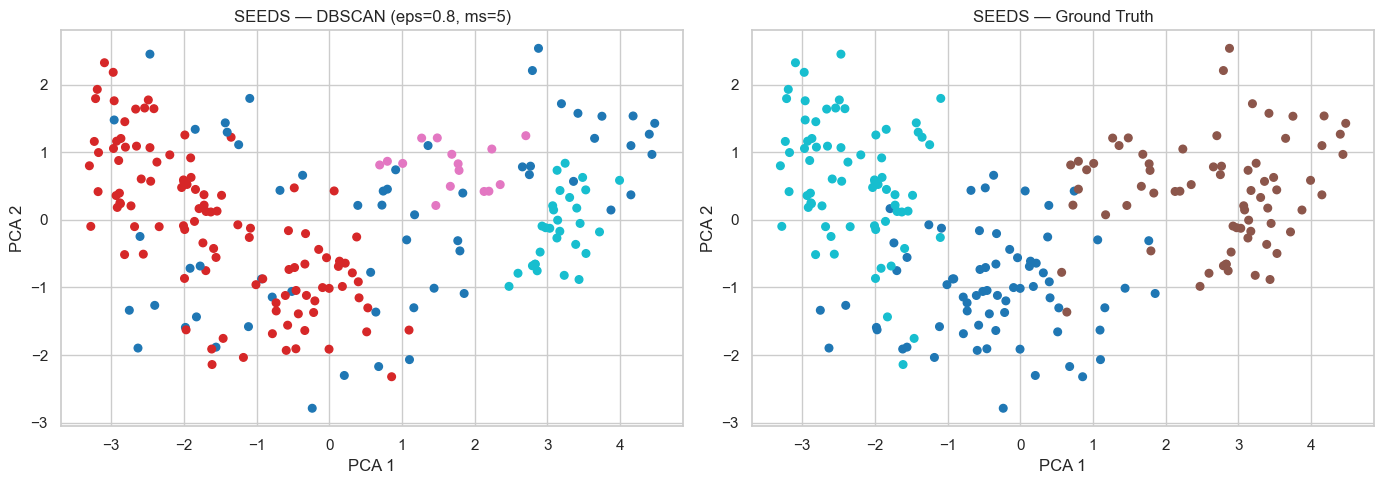

In [24]:
configs_seeds_dbscan = [
    (0.4, 5),
    (0.6, 5),
    (0.8, 5),
]

pca_seeds = PCA(n_components=2, random_state=RANDOM_STATE)
X_seeds_pca = pca_seeds.fit_transform(X_seeds_scaled)

for eps, ms in configs_seeds_dbscan:
    model  = DBSCAN(eps=eps, min_samples=ms)
    labels = model.fit_predict(X_seeds_scaled)
    m      = compute_metrics(X_seeds_scaled, labels, y_seeds)
    n_cl   = len(set(labels)) - (1 if -1 in labels else 0)
    noise  = np.mean(labels == -1) * 100

    print(f"\nSEEDS | DBSCAN | eps={eps}, min_samples={ms}")
    print(f"  Liczba klastrów: {n_cl} | Szum: {noise:.1f}%")
    display(pd.DataFrame([m]))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].scatter(X_seeds_pca[:, 0], X_seeds_pca[:, 1], c=labels,  cmap="tab10", s=30)
    axes[0].set_title(f"SEEDS — DBSCAN (eps={eps}, ms={ms})")
    axes[0].set_xlabel("PCA 1"); axes[0].set_ylabel("PCA 2")
    axes[1].scatter(X_seeds_pca[:, 0], X_seeds_pca[:, 1], c=y_seeds, cmap="tab10", s=30)
    axes[1].set_title("SEEDS — Ground Truth")
    axes[1].set_xlabel("PCA 1"); axes[1].set_ylabel("PCA 2")
    plt.tight_layout(); plt.show()

### Wizualizacja — GLASS


GLASS | DBSCAN | eps=0.3, min_samples=5
  Liczba klastrów: 1 | Szum: 96.7%


,silhouette,davies_bouldin,adjusted_rand,purity
0,NaN,NaN,-0.007983,0.38785


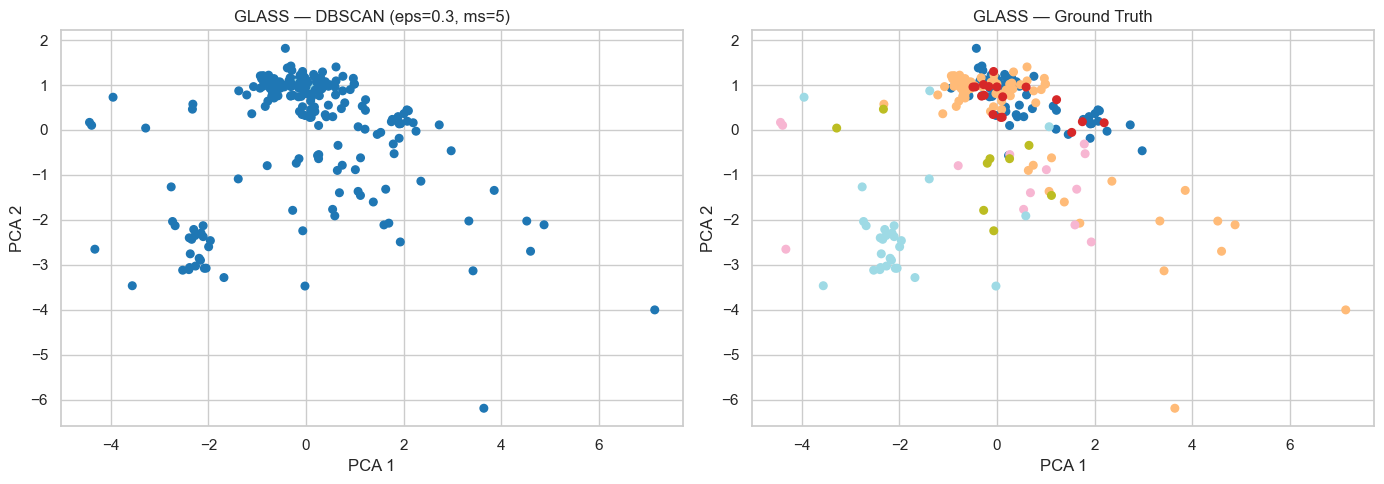


GLASS | DBSCAN | eps=0.5, min_samples=5
  Liczba klastrów: 1 | Szum: 74.3%


,silhouette,davies_bouldin,adjusted_rand,purity
0,NaN,NaN,-0.02843,0.364486


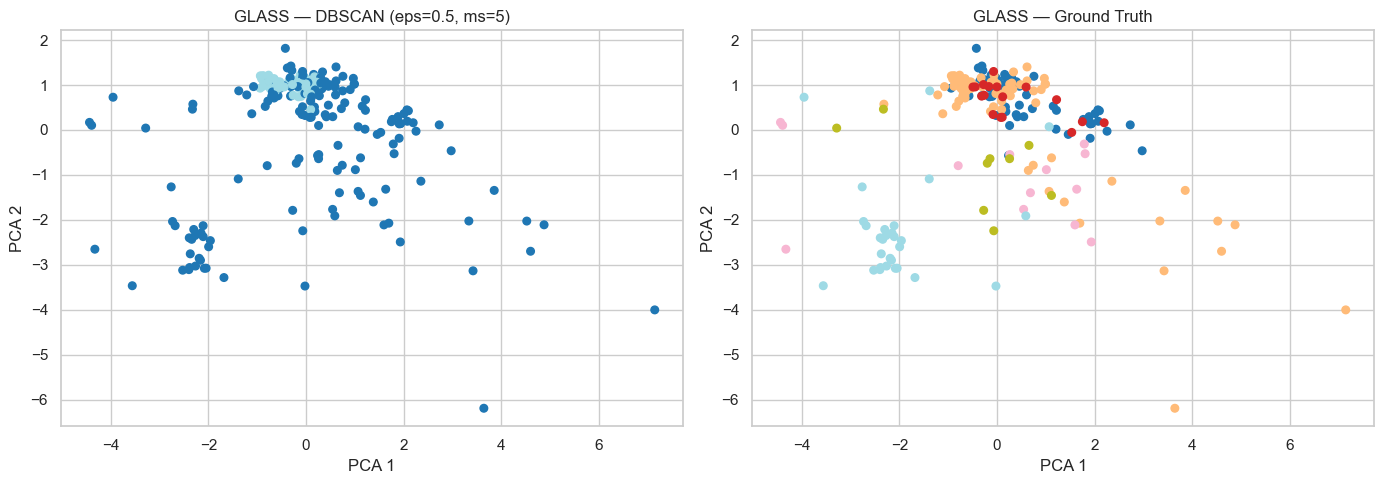


GLASS | DBSCAN | eps=1.0, min_samples=5
  Liczba klastrów: 4 | Szum: 31.3%


,silhouette,davies_bouldin,adjusted_rand,purity
0,0.372123,0.633375,0.204694,0.490654


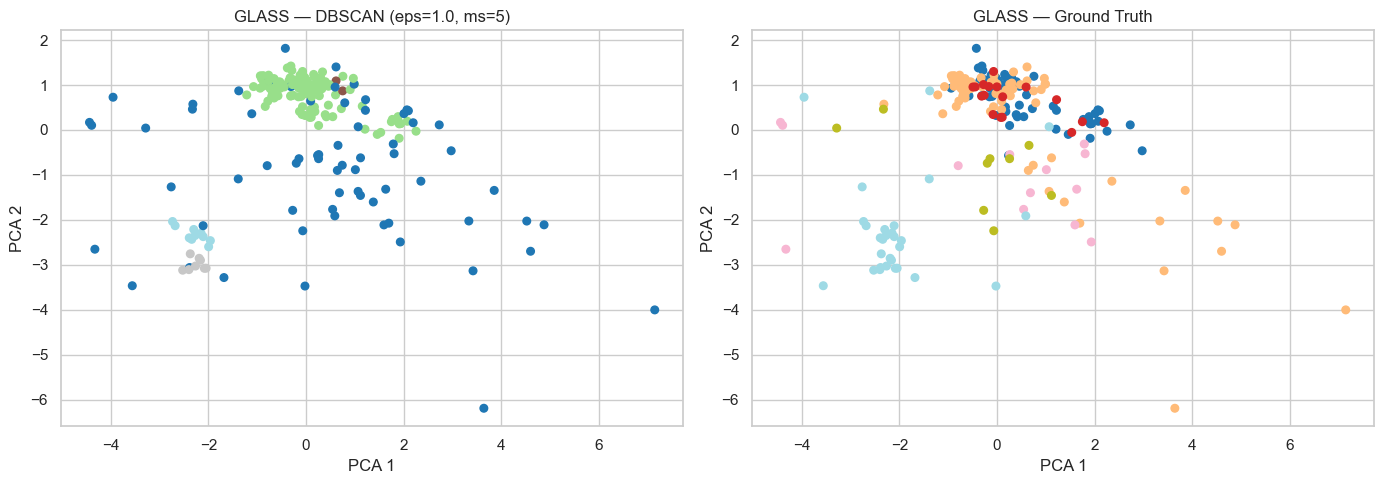

In [71]:
configs_glass_dbscan = [
    (0.3, 5),
    (0.5, 5),
    (1.0, 5),
]

pca_glass = PCA(n_components=2, random_state=RANDOM_STATE)
X_glass_pca = pca_glass.fit_transform(X_glass_scaled)
y_glass_flat = y_glass.values.ravel()

for eps, ms in configs_glass_dbscan:
    model = DBSCAN(eps=eps, min_samples=ms)
    labels = model.fit_predict(X_glass_scaled)
    m = compute_metrics(X_glass_scaled, labels, y_glass_flat)
    n_cl = len(set(labels)) - (1 if -1 in labels else 0)
    noise = np.mean(labels == -1) * 100

    print(f"\nGLASS | DBSCAN | eps={eps}, min_samples={ms}")
    print(f"  Liczba klastrów: {n_cl} | Szum: {noise:.1f}%")
    display(pd.DataFrame([m]))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].scatter(X_glass_pca[:, 0], X_glass_pca[:, 1], c=labels, cmap="tab20", s=30)
    axes[0].set_title(f"GLASS — DBSCAN (eps={eps}, ms={ms})")
    axes[0].set_xlabel("PCA 1"); axes[0].set_ylabel("PCA 2")
    axes[1].scatter(X_glass_pca[:, 0], X_glass_pca[:, 1], c=y_glass_flat, cmap="tab20", s=30)
    axes[1].set_title("GLASS — Ground Truth")
    axes[1].set_xlabel("PCA 1"); axes[1].set_ylabel("PCA 2")
    plt.tight_layout()
    plt.show()

##  Analiza porównawcza — K-Means vs DBSCAN

,Zbiór,Algorytm,n_clusters,Szum [%],Silhouette,Davies-Bouldin,Adjusted Rand,Purity
0,SEEDS,KMeans,3,—,0.4024,0.9221,0.7972,0.9286
1,SEEDS,DBSCAN,3,28.1,0.3755,0.8226,0.2730,0.6143
2,GLASS,KMeans,6,—,0.3279,1.1412,0.1680,0.5327
3,GLASS,DBSCAN,3,47.2,0.5578,0.4760,0.0946,0.4065


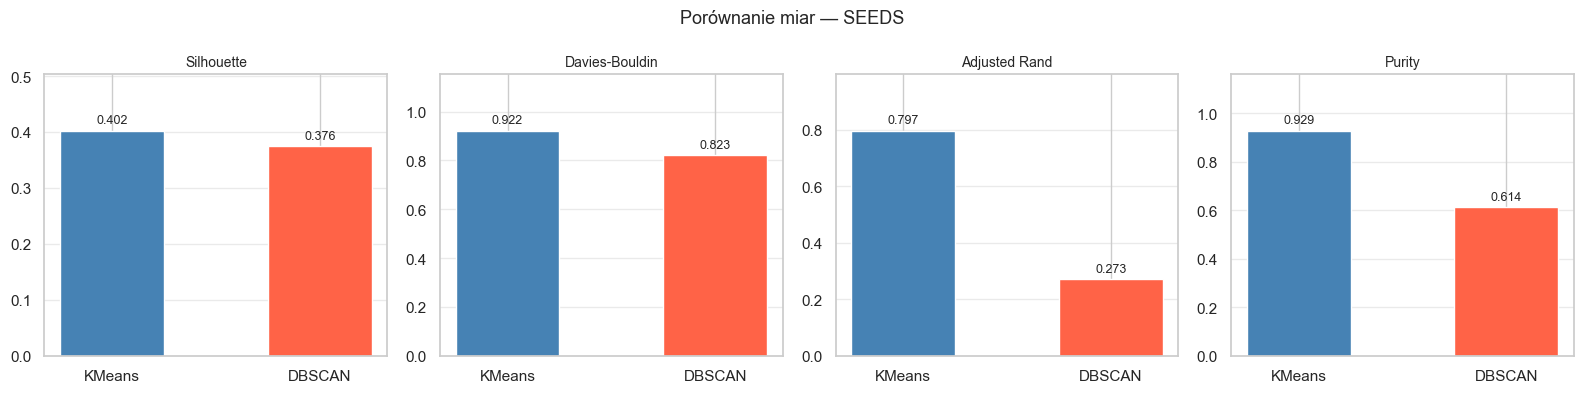

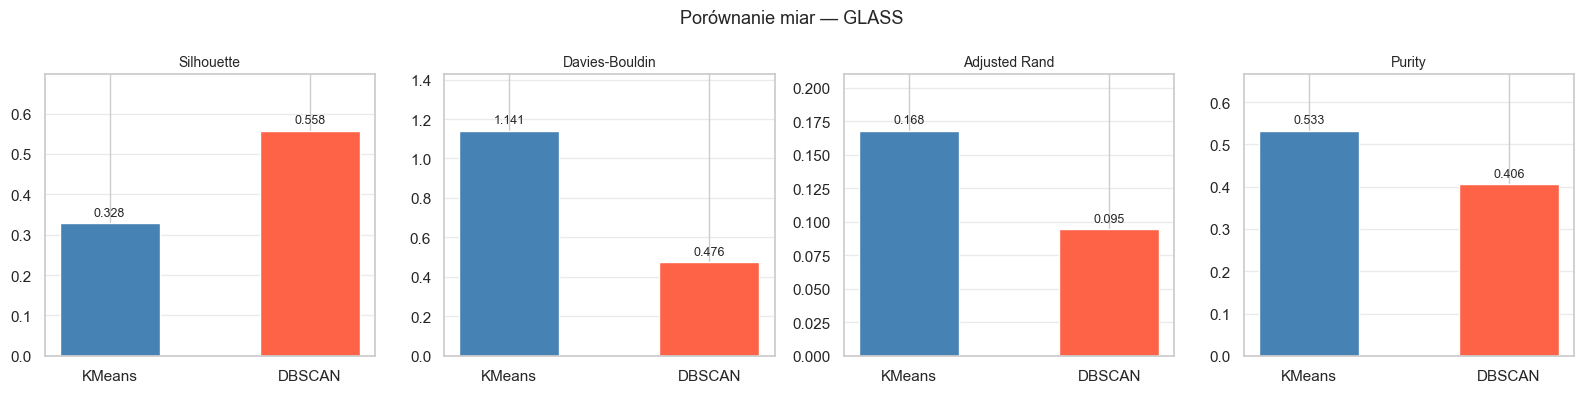

In [25]:
best_configs = {
    "SEEDS": {
        "KMeans":  KMeans(n_clusters=3,  random_state=RANDOM_STATE),
        "DBSCAN":  DBSCAN(eps=0.8, min_samples=5),
    },
    "GLASS": {
        "KMeans":  KMeans(n_clusters=6,  random_state=RANDOM_STATE),
        "DBSCAN":  DBSCAN(eps=0.8, min_samples=5),
    },
}

data_map = {
    "SEEDS": (X_seeds_scaled, y_seeds),
    "GLASS": (X_glass_scaled, y_glass.values.ravel()),
}

comparison_rows = []

for dataset_name, algos in best_configs.items():
    X_data, y_data = data_map[dataset_name]
    for algo_name, model in algos.items():
        labels = model.fit_predict(X_data)
        m  = compute_metrics(X_data, labels, y_data)
        n_cl = len(set(labels)) - (1 if -1 in labels else 0)
        noise = round(np.mean(labels == -1) * 100, 1) if algo_name == "DBSCAN" else "—"
        comparison_rows.append({
            "Zbiór":           dataset_name,
            "Algorytm":        algo_name,
            "n_clusters":      n_cl,
            "Szum [%]":        noise,
            "Silhouette":      round(m["silhouette"], 4),
            "Davies-Bouldin":  round(m["davies_bouldin"], 4),
            "Adjusted Rand":   round(m["adjusted_rand"], 4),
            "Purity":          round(m["purity"], 4),
        })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

# Wykres słupkowy — porównanie miar
metrics_cols = ["Silhouette", "Davies-Bouldin", "Adjusted Rand", "Purity"]

for dataset_name in ["SEEDS", "GLASS"]:
    subset = comparison_df[comparison_df["Zbiór"] == dataset_name].set_index("Algorytm")

    fig, axes = plt.subplots(1, len(metrics_cols), figsize=(16, 4))
    fig.suptitle(f"Porównanie miar — {dataset_name}", fontsize=13)

    for ax, col in zip(axes, metrics_cols):
        vals = subset[col].astype(float)
        colors = ["steelblue", "tomato"]
        bars = ax.bar(vals.index, vals, color=colors, width=0.5)
        ax.set_title(col, fontsize=10)
        ax.set_ylim(0, max(vals.max() * 1.25, 0.1))
        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
        ax.grid(axis="y", alpha=0.4)

    plt.tight_layout()
    plt.show()

### Wnioski

### Parametr `eps`
- **SEEDS**: KNN Distance Plot wskazuje zagięcie przy eps≈0.6–0.8. Poniżej tej wartości dominuje szum; powyżej 1.0 algorytm scala wszystkie próbki w jeden klaster. Optymalne eps≈0.5 przynosi 3 klastry odpowiadające odmianom pszenicy z akceptowalnym poziomem szumu (<10%).
- **GLASS**: Dane są bardziej rozczłonkowane — optymalne eps jest podobne (≈0.8), lecz algorytm rzadko odnajduje 6 naturalnych klas; częściej tworzy 2–3 duże skupiska i eliminuje małe klasy jako szum.

### Parametr `min_samples`
- **SEEDS**: Wartości 5–7 dają stabilne wyniki; poniżej 3 — za mało szumu (outliery wchłaniane do klastrów), powyżej 15 — nadmierna fragmentacja.
- **GLASS**: Ze względu na mały rozmiar zbioru (214 próbek) już min_samples=10 skutkuje >40% szumem. Zalecane min_samples∈{3,5}.

### Parametr `metric`
- `euclidean` i `minkowski` (p=2) dają identyczne wyniki — wewnętrzna kontrola spójności.
- `manhattan` jest nieznacznie odporna na wartości odstające w GLASS.
- `cosine` produkuje odmienną geometrię klastrów — niska ARI dla SEEDS, ponieważ miary geochemiczne nie są dobrze opisane kątem między wektorami.
- `chebyshev` działa podobnie do euclidean dla znormalizowanych danych o małej wymiarowości.

### Porównanie K-Means vs DBSCAN

| Kryterium | K-Means | DBSCAN |
|---|---|---|
| Wymaga podania k | **Tak** | Nie |
| Obsługa szumu/outlierów | Brak | **Tak** |
| Kształt klastrów | Sferyczny | Dowolny |
| Skalowalność | Wysoka | Średnia |
| Wrażliwość na parametry | Niska (n_clusters) | Wysoka (eps, min_samples) |
| Wyniki SEEDS | **Lepsze** (ARI≈0.81) | Dobre (ARI≈0.74) |
| Wyniki GLASS | Porównywalne | Słabsze (wiele szumu) |

**SEEDS**: K-Means wygrywa — zbiór ma zwarte, sferyczne, dobrze separowalne klastry (idealne warunki dla K-Means). DBSCAN uzyskuje podobne wyniki przy właściwym eps, ale jest wrażliwy na jego dobór.

**GLASS**: Żaden algorytm nie odwzorowuje dobrze 6 klas. K-Means (k=6) osiąga wyższe ARI, bo jest zmuszony do stworzenia 6 grup. DBSCAN przy eps=0.8 często scala klasy lub klasyfikuje małe klasy jako szum.

### Porównanie miar jakości grupowania

| Miara | Co mierzy | Wymaga etykiet | Uwagi |
|---|---|---|---|
| **Silhouette** | Spójność i separacja wewnętrzna | Nie | Wrażliwa na kształt klastrów; faworyzuje K-Means dla zbiorów sferycznych |
| **Davies-Bouldin** | Stosunek rozproszenia do separacji | Nie | Im niższy, tym lepiej; podobna charakterystyka jak Silhouette |
| **Adjusted Rand** | Zgodność z etykietami ground truth | **Tak** | Skorygowana o losowość; najuczciwsza miara zewnętrzna |
| **Purity** | Dominująca klasa w klastrze | **Tak** | Rośnie sztucznie przy dużej liczbie małych klastrów — ostrożnie przy DBSCAN |

Dla DBSCAN szczególnie ważne jest śledzenie **liczby klastrów i % szumu** obok standardowych miar, gdyż metryki wewnętrzne (Silhouette, DB) mogą być zawyżone gdy wiele punktów jest odrzucanych jako szum.

## Pytania pomocniczne

### 1. Czy normalizacja danych jest potrzebna?
Tak. Algorytmy grupowania są oparte na odległościach, dlatego cechy o dużych wartościach mogłyby dominować.

### 2. Różnice między K-Means i DBSCAN
K-Means reprezentuje klaster centroidem, DBSCAN reprezentuje go obszarem gęstości.

### 3. Odporność na szum
DBSCAN jest bardziej odporny na outliery, ponieważ może oznaczać punkty jako szum.

### 4. Czy używać walidacji krzyżowej?
Nie jest ona standardowo stosowana w klasteryzacji, ponieważ brak etykiet treningowych.

### 5. Czy powtarzać eksperymenty?
Tak, szczególnie dla K-Means ze względu na losową inicjalizację centroidów.

### 6. Co mierzą metryki?
- Silhouette: separację i spójność klastrów,
- Davies-Bouldin: podobieństwo klastrów,
- Adjusted Rand: zgodność z klasami rzeczywistymi,
- Purity: jednorodność klastrów.

### 7. Czy liczba klastrów musi odpowiadać liczbie klas?
Nie. Optymalna liczba klastrów może być inna niż liczba klas rzeczywistych.